# IMF Country Report → AI Pipeline → Financial Stability Dashboard

**Student ID:** 24161377  
**Allocation:** Vietnam  
**Report used:** IMF Country Report No. 25/283 – *Vietnam: 2025 Article IV Consultation—Press Release; Staff Report; and Statement by the Executive Director for Vietnam* (2025)

This project analyses the IMF's 2025 Article IV report on Vietnam. The report examines Vietnam's recent economic developments, macroeconomic outlook, financial stability, policy discussions and structural challenges.

**How to run it:** Open the notebook in Google Colab and select **Runtime → Run all**. The following setup is required first:

1. **IMF report PDF:** Upload the Vietnam IMF report to Google Colab. The notebook uses the configured PDF path: `/content/1934-7685-002.2025.issue-283-en.pdf`.
2. **Gemini API key:** Save your Gemini API key in Google Colab Secrets under the name `GEMINI_API_KEY`.

The notebook processes the report and produces summaries, structured financial indicators, retrieval results, evaluation outputs and dashboard visualisations. Generated outputs are saved in the configured `vietnam_imf_outputs` directory.

| Section | What I do there |
|---|---|
| **0. Setup** | Import libraries, configure project settings, connect to the required files, set up Gemini and define reusable functions for language-model requests. |
| **Task 1 – PDF Processing and Summarisation** | Extract and clean the IMF PDF, divide the report into chunks and sections, generate section and executive summaries, and evaluate their consistency, completeness and factual accuracy. |
| **Task 2 – Financial Stability Analysis** | Analyse seven financial-stability themes, extract economic strengths and vulnerabilities, create structured numerical indicator outputs, identify historical and projected trends, and validate the results. |
| **Task 3 – Retrieval-Augmented Generation (RAG)** | Create document embeddings using MiniLM and BGE, build FAISS indexes, retrieve relevant report passages, generate evidence-based answers and evaluate retrieval and citation quality. |
| **Extension – Multi-Query RAG** | Generate alternative question formulations, combine retrieval results using Reciprocal Rank Fusion, and compare Multi-Query RAG with standard single-query retrieval. |
| **Extension – Model Benchmarking** | Compare Gemini Flash model variants using JSON schema compliance, numerical extraction accuracy, response latency and LLM-as-a-Judge evaluation scores. |
| **Task 4 – Visualisation and Dashboard** | Reshape data using `pd.melt`, create financial-stability charts, compare retrieval and evaluation results, and produce the final Vietnam dashboard. |
| **Final Checks** | Run validation tests, record software versions, review generated files and compile the final project outputs. |

**Project objective:** To develop an AI-assisted analytical pipeline that extracts, summarises, evaluates and visualises information from the Vietnam IMF Article IV report, with particular attention to macroeconomic conditions, financial stability risks and policy recommendations.

### 0.1 Libraries

I use `pypdf` to read and extract text from the Vietnam IMF Article IV 2025 report, `tiktoken` to count tokens and create text chunks, `google-genai` to access Gemini models for information extraction and evaluation, and `sentence-transformers` with `faiss-cpu` to generate embeddings and perform similarity-based retrieval for Task 3.

In [ ]:
!pip install -q pypdf tiktoken google-genai sentence-transformers faiss-cpu

### 0.2 Configuration

I put every file path, model name and project setting in one place so that I do not need to repeat them throughout the notebook and can easily make changes when needed.

I use two groups of Gemini models. The **extractor models** generate section summaries, extract macroeconomic and financial indicators, identify trends and answer the RAG questions. The **judge models** independently evaluate the extracted information, summaries and RAG answers to check their quality and reliability.

I keep separate lists of backup models for both groups because the Gemini free tier sometimes returned `429` (rate limit) and `503` (service unavailable) errors during the project. If one model fails, the notebook automatically tries the next available model. I also record which model successfully produced each output to make the results easier to track and reproduce.

The configuration includes the country name (Vietnam), report year (2025), PDF location, output folder, model settings, temperature, retry and rate-limit settings, and text chunking parameters. Keeping these settings together makes it easier to reuse the same workflow and maintain consistency across the different tasks.

In [ ]:
import os
import sys
import re
import json
import time
import math
import pandas as pd
import numpy as np

IN_COLAB = "google.colab" in sys.modules

DRIVE_ROOT = "/content/drive/MyDrive" if IN_COLAB else os.path.expanduser("~/Downloads")
PDF_PATH = (
    "/content/1934-7685-002.2025.issue-283-en.pdf"
    if IN_COLAB else
    os.path.join(DRIVE_ROOT, "1934-7685-002.2025.issue-283-en.pdf")
)

OUT_DIR = os.path.join(DRIVE_ROOT, "vietnam_imf_outputs")
CACHE_DIR = os.path.join(OUT_DIR, "cache")
FIG_DIR = os.path.join(OUT_DIR, "figures")

COUNTRY = "Vietnam"

# Extractor and judge models (must be mutually exclusive)
EXTRACT_MODELS = ["gemini-3.5-flash", "gemini-3-flash-preview", "gemini-3.6-flash",
                  "gemini-3.7-flash", "gemini-3.8-flash", "gemini-flash-latest"]
JUDGE_MODELS   = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite"]

TEMPERATURE = 0.0
MIN_GAP_S = 4

print("Country:", COUNTRY)
print("PDF path:", PDF_PATH)
print("Running in Colab:", IN_COLAB)

Country: Vietnam
PDF path: /content/1934-7685-002.2025.issue-283-en.pdf
Running in Colab: True


In [ ]:
# Chunking (brief suggests 300-500 tokens with ~50-token overlap)
CHUNK_TOKENS   = 350          # leaves head-room under BGE's 512-token limit (see Task 3)
CHUNK_OVERLAP  = 50

# Retrieval
EMBED_MODELS = {"MiniLM": "sentence-transformers/all-MiniLM-L6-v2",   # baseline
                "BGE":    "BAAI/bge-small-en-v1.5"}                   # chosen model
QUERY_PREFIX = {"MiniLM": "", "BGE": "Represent this sentence for searching relevant passages: "}
TOP_K   = 5                   # baseline context size
MQ_K    = 8                   # broader context for Multi-Query RAG (extension)
RRF_K   = 60                  # standard Reciprocal Rank Fusion constant
SEED    = 42

FALLBACK = -1.0               # value for an indicator the report does not state
print("Config ready")

Config ready


In [ ]:
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")

    uploaded = files.upload()
    PDF_PATH = "/content/1934-7685-002.2025.issue-283-en.pdf"

for d in (OUT_DIR, CACHE_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

assert os.path.exists(PDF_PATH), (
    f"Vietnam IMF PDF not found at {PDF_PATH}. "
    "Please upload 1934-7685-002.2025.issue-283-en(1).pdf."
)

print("PDF found:", PDF_PATH)
print("Country  :", COUNTRY)
print("Outputs  :", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving 1934-7685-002.2025.issue-283-en.pdf to 1934-7685-002.2025.issue-283-en.pdf
PDF found: /content/1934-7685-002.2025.issue-283-en.pdf
Country  : Vietnam
Outputs  : /content/drive/MyDrive/vietnam_imf_outputs


In [ ]:
import os
print(os.listdir("/content"))

['.config', 'drive', '1934-7685-002.2025.issue-283-en.pdf', 'sample_data']


### 0.3 Gemini client and model availability

The Gemini API key is read securely from Colab Secrets when running in Google Colab, or from an environment variable when running locally. This means the API key is not written directly in the notebook or exposed when the project is shared.

After creating the Gemini client, I check which models are available to the user's API key using the Gemini API model-listing method. I then compare the available models with my extractor and judge model lists to identify which models can be used before starting the analysis.

I added this availability check because I encountered a `404` error when initially trying to use `gemini-2.5-flash`. Model names and access can differ depending on API availability, so checking them at the beginning helps avoid failures halfway through the Vietnam IMF report analysis.

The notebook also checks whether the models support content generation before adding them to the available model lists. This helps the extractor and judge functions select valid models and use backup models when a request fails.

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata
import os

API_KEY = userdata.get("GEMINI_API_KEY") if IN_COLAB else os.environ.get("GEMINI_API_KEY")
client = genai.Client(api_key=API_KEY)

try:
    available = {m.name.split("/")[-1] for m in client.models.list()}
    EXTRACT_MODELS = [m for m in EXTRACT_MODELS if m in available]
    JUDGE_MODELS   = [m for m in JUDGE_MODELS if m in available]
except Exception as e:                       # listing can fail transiently; keep config as-is
    print("Could not list models, using configured lists:", str(e)[:80])

assert EXTRACT_MODELS and JUDGE_MODELS, "No usable models for one of the roles"
assert not set(EXTRACT_MODELS) & set(JUDGE_MODELS), "Extractor and judge must differ"
print("Extractor models:", EXTRACT_MODELS)
print("Judge models    :", JUDGE_MODELS)

Extractor models: ['gemini-3.5-flash', 'gemini-3-flash-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-flash-latest']
Judge models    : ['gemini-3.5-flash-lite', 'gemini-3.1-flash-lite']


### 0.4 One helper for every LLM call

Every Gemini API call in the notebook goes through the `llm()` function. This keeps model calls consistent across the Vietnam IMF report analysis and makes the workflow easier to manage.

It performs four main tasks:

- **Caching.** Each response is saved locally in `cache/llm_cache.json`, using a hash of the prompt and relevant model settings as the cache key. If the same request is made again, the saved response is reused without making another API call. This reduces API usage and saves time when rerunning notebook cells.

- **Fallback.** If a model returns an invalid response or encounters a temporary error, the next available model is tried. If a model is busy or the API quota is exceeded, the function waits before retrying. This helps the analysis continue without depending on a single Gemini model.

- **Recording.** Every response is stored with information about the model that produced it, the time taken and whether the result came from the cache. This makes the extraction and evaluation process easier to track.

- **Failing clearly.** If all available models fail, the function raises an error instead of silently returning an empty result. I added this because an earlier version of the notebook could print "done" even when no summary had been generated, making it difficult to identify failed extraction steps.

Using one helper for all LLM calls also makes the notebook more portable, because the same caching, retry, fallback and logging behaviour is applied to summaries, indicator extraction, trend analysis and RAG evaluation.

In [ ]:
LLM_CACHE_PATH = os.path.join(CACHE_DIR, "llm_cache.json")

def load_json(path, default):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default

def save_json(obj, path):
    # write to a temp file first, so an interrupted run never leaves a corrupt file
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)
    os.replace(tmp, path)

llm_cache = load_json(LLM_CACHE_PATH, {})
print(f"LLM cache: {len(llm_cache)} saved answers")


LLM cache: 47 saved answers


In [ ]:
LLM_CACHE_PATH = os.path.join(CACHE_DIR, "llm_cache.json")

def load_json(path, default):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default

def save_json(obj, path):
    # write to a temp file first, so an interrupted run never leaves a corrupt file
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)
    os.replace(tmp, path)

llm_cache = load_json(LLM_CACHE_PATH, {})
print(f"LLM cache: {len(llm_cache)} saved answers")

LLM cache: 47 saved answers


In [ ]:
def _error_kind(e):
    m = str(e)
    if "429" in m or "RESOURCE_EXHAUSTED" in m: return "quota limit"
    if "503" in m or "UNAVAILABLE" in m or "overloaded" in m.lower(): return "server busy"
    if "404" in m or "NOT_FOUND" in m: return "model not available"
    return m[:60]

def _call_gemini(model, prompt, system, json_mode):
    cfg = types.GenerateContentConfig(
        temperature=TEMPERATURE, system_instruction=system,
        response_mime_type="application/json" if json_mode else "text/plain")
    t0 = time.time()
    r = client.models.generate_content(model=model, contents=prompt, config=cfg)
    if not r.text:
        raise ValueError("empty response")
    return r.text, round(time.time() - t0, 2)

In [ ]:
_unavailable, _last_call = set(), [0.0]
CALL_STATS = Counter()            # answers served from cache vs fresh API calls in this run

def llm(prompt, role="extract", system=None, json_mode=False, rounds=3):
    # Cached Gemini call with model fallback. Returns {text, model, latency, cached}.
    key = hashlib.sha256(json.dumps([role, system, json_mode, prompt]).encode()).hexdigest()
    if key in llm_cache:
        CALL_STATS["from cache"] += 1
        return {**llm_cache[key], "cached": True}

    CALL_STATS["api calls"] += 1
    models = EXTRACT_MODELS if role == "extract" else JUDGE_MODELS
    for rnd in range(rounds):
        for m in [m for m in models if m not in _unavailable]:
            time.sleep(max(0, MIN_GAP_S - (time.time() - _last_call[0])))
            _last_call[0] = time.time()
            try:
                text, latency = _call_gemini(m, prompt, system, json_mode)
                llm_cache[key] = {"text": text, "model": m, "latency": latency, "role": role}
                save_json(llm_cache, LLM_CACHE_PATH)
                return {**llm_cache[key], "cached": False}
            except Exception as e:
                kind = _error_kind(e)
                print(f"  {m}: {kind}, trying next")
                if kind == "model not available":
                    _unavailable.add(m)
        if rnd < rounds - 1:
            print(f"  all {role} models busy - waiting {30 * (rnd + 1)}s")
            time.sleep(30 * (rnd + 1))
    raise RuntimeError(f"All {role} models failed. Completed calls are cached - re-run this cell later.")

In [ ]:
def parse_json(text):
    # Parse model JSON robustly: strip ``` fences; if needed, cut out the outermost {...} or [...].
    text = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        starts = [i for i in (text.find("{"), text.find("[")) if i != -1]
        if not starts:
            raise
        start = min(starts)
        end = text.rfind("}" if text[start] == "{" else "]")
        return json.loads(text[start:end + 1])

def llm_json(prompt, role="extract", system=None):
    # JSON-mode call; if the reply is not valid JSON, ask once for a repaired version.
    res = llm(prompt, role=role, system=system, json_mode=True)
    try:
        return parse_json(res["text"]), res
    except (json.JSONDecodeError, ValueError):
        print("  invalid JSON - asking the model to repair it")
        fix = llm("Return ONLY the valid JSON equivalent of this text, nothing else:\n\n" + res["text"],
                  role=role, json_mode=True)
        return parse_json(fix["text"]), fix

In [ ]:
# smoke test: one tiny call per role (cached after the first run)
for role in ("extract", "judge"):
    r = llm("Reply with the single word: ready", role=role)
    print(f"{role:8s} -> {r['text'].strip()!r:10s} model={r['model']}  cached={r['cached']}")

extract  -> 'ready'    model=gemini-3.5-flash  cached=True
judge    -> 'Ready'    model=gemini-3.5-flash-lite  cached=True


# Task 1 – PDF Processing Pipeline & Summarisation

### 1.1 Document ingestion

I read the Vietnam IMF Article IV Consultation 2025 report page by page using `pypdf`. The report year (2025) and report number (25/283) are identified from the document text rather than being manually entered. I use the extracted report information later in the notebook, particularly when identifying historical and projected years in the IMF tables and figures.

**Task 1: PDF Processing Pipeline & Summarisation**

- **Document Ingestion:** Load the assigned Vietnam IMF Article IV Consultation report (IMF Country Report No. 25/283), identified through the Student Allocation Lookup Table on Canvas.
- **Extraction & Cleaning:** Extract the report text page by page using `pypdf`. Clean unnecessary line breaks, repeated headers and footers, and formatting artefacts while preserving important financial figures, tables and section headings.
- **Token-Aware Chunking:** Divide the extracted text into meaningful, overlapping chunks using `tiktoken`. I use a 350-token chunk budget and 50-token overlap to maintain context between consecutive chunks and reduce information loss.
- **Executive Summary:** Use Gemini to generate concise bullet points covering the main financial stability findings, macroeconomic developments, vulnerabilities and risk assessments identified throughout the Vietnam report.
- **Chapter / Section Summarisation:** Generate individual summaries of the major report sections, keeping each summary below 100 words and retaining important figures and findings.
- **Dual-LLM / Evaluator Framework:** Use separate extractor and judge model groups. The extractor models generate the summaries and extracted information, while the judge models independently assess their consistency, completeness and factual alignment with the original report. This helps identify unsupported claims, missing information and potential inaccuracies in the generated summaries.

# Task 1 – PDF Processing Pipeline & Summarisation

### 1.1 Document ingestion

I read the Vietnam IMF Article IV Consultation 2025 report page by page using `pypdf`. The report year and report number are extracted from the document text itself instead of being typed manually. I use the report year later to identify which years in the IMF tables and figures are projections.

In [ ]:
reader = PdfReader(PDF_PATH)
pages = [p.extract_text() or "" for p in reader.pages]

front = " ".join(pages[:3])
REPORT_YEAR = int(re.search(r"(20\d\d) ARTICLE IV CONSULTATION", front).group(1))
REPORT_NO   = re.search(r"Country Report No\.\s*(\d+/\d+)", front).group(1)

print(f"Pages: {len(pages)} | raw characters: {sum(map(len, pages)):,}")
print(f"Report: IMF Country Report No. {REPORT_NO} | Article IV year: {REPORT_YEAR}")

Pages: 73 | raw characters: 153,894
Report: IMF Country Report No. 25/283 | Article IV year: 2025


### 1.2 Extraction & cleaning

I printed some raw pages from the Vietnam IMF report first to see what needed cleaning, and wrote one rule for each problem:

| **Problem in the raw text** | **What I did** |
|---|---|
| "VIETNAM" and repeated IMF report headings printed across pages | Removed lines that appear on at least 30% of pages, so the code identifies repeated headers automatically. |
| Page numbers, "INTERNATIONAL MONETARY FUND" and copyright lines | Removed them using simple text patterns. |
| Contents-page entries and dotted or underscored leader lines | Removed lines containing repeated underscores or formatting leaders, which could otherwise create unnecessarily large chunks. |
| Sentences broken over several lines | Joined line breaks when they clearly occur in the middle of a sentence. |
| Words split by a hyphen at the end of a line | Preserved genuine hyphenated words rather than joining them incorrectly. |
| Different dash and minus characters | Normalised them to a standard hyphen (`-`) to make text and numerical matching more consistent. |

In [ ]:
def find_repeated_lines(pages, min_frac=0.3):
    counts = Counter()
    for p in pages:
        counts.update({line.strip() for line in p.splitlines() if line.strip()})
    return {line for line, c in counts.items() if c >= min_frac * len(pages)}

REPEATED = find_repeated_lines(pages)
DASHES = dict.fromkeys(map(ord, "‐‑‒−"), "-")   # hyphen variants + minus -> "-"
removed = Counter()                                                  # how many lines each rule removed
print("Detected running headers/footers:", REPEATED)

Detected running headers/footers: {'VIETNAM', '©International Monetary Fund. Not for Redistribution'}


In [ ]:
def drop_line(s):
    # Return the name of the cleaning rule that removes this line, or None to keep it.
    if not s:                                     return "blank"
    if s in REPEATED:                             return "header/footer"
    if re.fullmatch(r"-?\d{1,3}", s):             return "page number / chart axis value"
    if re.search(r"INTERNATIONAL MONETARY FUND|©\s*20\d\d", s): return "IMF banner"
    if re.search(r"_{3,}", s):                    return "TOC leader / separator"
    return None

def clean_page(text):
    text = unicodedata.normalize("NFKC", text).translate(DASHES)
    kept = []
    for line in text.splitlines():
        rule = drop_line(line.strip())
        if rule: removed[rule] += 1
        else:    kept.append(line.strip())
    t = "\n".join(kept)
    t = re.sub(r"(\w)-\n(\w)", r"\1-\2", t)                   # keep compound hyphens
    t = re.sub(r"(?<=[a-z0-9,;])\n(?=[a-z(])", " ", t)        # join lines broken mid-sentence
    t = re.sub(r"[ \t]+", " ", t)
    return t.strip()

In [ ]:
clean_pages = [clean_page(p) for p in pages]
full_text = "\n\n".join(clean_pages)

raw_chars = sum(map(len, pages))
print(f"Cleaned characters: {len(full_text):,} ({100 - 100 * len(full_text) / raw_chars:.1f}% removed)")
print("Lines removed by rule:", dict(removed))
with open(os.path.join(OUT_DIR, "cleaned_text.txt"), "w") as f:
    f.write(full_text)

Cleaned characters: 140,173 (8.9% removed)
Lines removed by rule: {'blank': 278, 'IMF banner': 63, 'header/footer': 137, 'page number / chart axis value': 422, 'TOC leader / separator': 33}


In [ ]:
# before / after on the Key Issues page
print("RAW:\n", pages[5][:600], "\n\nCLEAN:\n", clean_pages[5][:600])

RAW:
  
 
VIETNAM 
STAFF REPORT FOR THE 2025 ARTICLE IV CONSULTATION 
 
KEY ISSUES 
 
Context. Growth accelerated in 2024 supported by a rebound in exports and 
accommodative policies. However, the successful export-led growth model faces 
significant new challenges from a more adverse and uncertain global trade 
environment. The authorities are undertaking a major institutional restructuring, and 
planning reforms and scaling-up public investment to boost medium-term growth. 
 
Recommendations. Policies will need to be agile to manage a complex external 
environment amid elevated uncertainty and ri 

CLEAN:
 STAFF REPORT FOR THE 2025 ARTICLE IV CONSULTATION
KEY ISSUES
Context. Growth accelerated in 2024 supported by a rebound in exports and accommodative policies. However, the successful export-led growth model faces significant new challenges from a more adverse and uncertain global trade environment. The authorities are undertaking a major institutional restructuring, and planning r

**Does cleaning change the meaning?** Cleaning is only allowed to delete whole lines and to change spaces and dash characters. The validation check compares each cleaned page with the original lines that were retained. Once spaces and punctuation are normalised, the cleaned page should match the retained original text. This helps confirm that no words or numerical figures in the retained text have been unintentionally changed. The next cell lists examples of what each cleaning rule removed, so the changes can also be checked manually.

*One thing I noticed:* when the PDF breaks a line immediately after a dash, the sentence can remain split across two lines in the cleaned text. This does not necessarily affect reading, but it can cause a false "not found" result during exact quote matching. I therefore account for line breaks and dash differences in the quote-matching checks later in the notebook.

In [ ]:
def alnum(s):
    return re.sub(r"[^0-9a-z]", "", unicodedata.normalize("NFKC", s).translate(DASHES).lower())

def kept_lines(page):
    t = unicodedata.normalize("NFKC", page).translate(DASHES)
    return "\n".join(l.strip() for l in t.splitlines() if not drop_line(l.strip()))

identical = [alnum(kept_lines(p)) == alnum(c) for p, c in zip(pages, clean_pages)]
assert all(identical), f"cleaning altered kept text on pages {[i + 1 for i, ok in enumerate(identical) if not ok]}"
print(f"Kept text unchanged on {sum(identical)}/{len(pages)} pages (only whole lines removed)")

Kept text unchanged on 73/73 pages (only whole lines removed)


In [ ]:
removed_examples = defaultdict(list)
for p in pages:
    for line in unicodedata.normalize("NFKC", p).translate(DASHES).splitlines():
        rule = drop_line(line.strip())
        if rule and rule != "blank" and len(removed_examples[rule]) < 4:
            removed_examples[rule].append(line.strip()[:70])
for rule, ex in removed_examples.items():
    print(f"{rule}: {ex}")

IMF banner: ['© 2025 International Monetary Fund', '2 INTERNATIONAL MONETARY FUND', 'INTERNATIONAL MONETARY FUND 3', '4 INTERNATIONAL MONETARY FUND']
header/footer: ['VIETNAM', '©International Monetary Fund. Not for Redistribution', '©International Monetary Fund. Not for Redistribution', '©International Monetary Fund. Not for Redistribution']
page number / chart axis value: ['2', '3', '26', '-6']
TOC leader / separator: ['CONTEXT AND RECENT ECONOMIC DEVELOPMENTS _____________________________', 'OUTLOOK AND RISKS ____________________________________________________', 'POLICY DISCUSSION ____________________________________________________', 'A. Monetary and Exchange Rate Policy _________________________________']


### 1.3 Token-aware, sentence-aware chunking

My first version cut the text at fixed token intervals, which sometimes caused chunks to start or end in the middle of a sentence or word. I improved this by splitting the cleaned Vietnam report text into sentences and table rows, then adding them to a chunk until the next unit would take it over the 350-token budget. This helps preserve the meaning of the financial information and ensures that chunks normally end at a sentence or table-row boundary.

For the overlap, the next chunk starts with the last complete sentences or rows from the previous chunk, up to approximately 50 tokens. Because the overlap uses complete text units, important information near a chunk boundary is less likely to be lost during retrieval.

With the overlap included, chunks can contain approximately 400 tokens, which is within the assignment's suggested 300–500 token range. I chose a 350-token budget rather than 400 new tokens because the embedding model may count tokens differently from `tiktoken`. This also helps keep chunks within the embedding model's 512-token input limit.

In [ ]:
enc = tiktoken.get_encoding("cl100k_base")
def n_tokens(s): return len(enc.encode(s))

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])")

def page_units(page_no, text):
    # Split one page into sentence / table-row units: (page, paragraph_id, text, tokens).
    units = []
    for para_id, para in enumerate(text.split("\n")):
        for s in SENT_SPLIT.split(para.strip()):
            if s.strip():
                units.append((page_no, para_id, s.strip(), n_tokens(s)))
    return units

In [ ]:
HARD_SPLITS = [0]

def hard_split(unit, max_tokens):
    # Rare: a single unit longer than a chunk (e.g. a run-on table) is cut by tokens.
    HARD_SPLITS[0] += 1
    page, para, text, _ = unit
    toks = enc.encode(text)
    return [(page, para, enc.decode(toks[i:i + max_tokens]), len(toks[i:i + max_tokens]))
            for i in range(0, len(toks), max_tokens)]

def join_units(units):
    out = units[0][2]
    for prev, u in zip(units, units[1:]):
        same_para = (u[0], u[1]) == (prev[0], prev[1])
        out += (" " if same_para else "\n") + u[2]
    return out

In [ ]:
def chunk_document(pages, max_tokens=CHUNK_TOKENS, overlap=CHUNK_OVERLAP):
    units = [u for i, p in enumerate(pages, 1) for u in page_units(i, p)]
    units = [s for u in units for s in (hard_split(u, max_tokens) if u[3] > max_tokens else [u])]
    chunks, cur = [], []
    for u in units:
        if cur and sum(x[3] for x in cur) + u[3] > max_tokens:
            chunks.append(cur)
            carry = []                                   # trailing whole sentences as overlap
            for x in reversed(cur):
                if sum(c[3] for c in carry) + x[3] > overlap: break
                carry.insert(0, x)
            cur = carry
        cur.append(u)
    chunks.append(cur)
    return [{"chunk_id": i, "page": c[0][0], "page_end": c[-1][0],
             "n_tokens": n_tokens(join_units(c)), "text": join_units(c)} for i, c in enumerate(chunks)]

In [ ]:
chunks = chunk_document(clean_pages)
sizes = [c["n_tokens"] for c in chunks]

limit = CHUNK_TOKENS + CHUNK_OVERLAP + 10
oversized = [i for i, size in enumerate(sizes) if size > limit]

print(f"Chunks: {len(chunks)} | tokens min/median/max: {min(sizes)}/{int(np.median(sizes))}/{max(sizes)} "
      f"(budget {CHUNK_TOKENS} + overlap {CHUNK_OVERLAP})")

if oversized:
    print(f"WARNING: {len(oversized)} chunks exceed the limit of {limit} tokens: {oversized}")
else:
    print("Chunk size validation passed.")

print(f"Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: {HARD_SPLITS[0]}")
punct = np.mean([bool(re.search(r"[.!?]\s*$", c["text"])) for c in chunks])
print(f"Chunks ending with sentence punctuation: {100 * punct:.0f}% (the rest end on a table row or heading)")

save_json(chunks, os.path.join(OUT_DIR, "chunks.json"))

Chunks: 107 | tokens min/median/max: 142/346/437 (budget 350 + overlap 50)
Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: 0
Chunks ending with sentence punctuation: 56% (the rest end on a table row or heading)


In [ ]:
print("CHUNK_TOKENS:", CHUNK_TOKENS)
print("CHUNK_OVERLAP:", CHUNK_OVERLAP)
print("Maximum allowed:", CHUNK_TOKENS + CHUNK_OVERLAP + 10)
print("Largest chunk:", max(sizes))

large_chunks = [(i, s) for i, s in enumerate(sizes)
                if s > CHUNK_TOKENS + CHUNK_OVERLAP + 10]

print("Number of oversized chunks:", len(large_chunks))
print("Oversized chunk examples:", large_chunks[:10])

CHUNK_TOKENS: 350
CHUNK_OVERLAP: 50
Maximum allowed: 410
Largest chunk: 437
Number of oversized chunks: 3
Oversized chunk examples: [(45, 420), (47, 419), (48, 437)]


In [ ]:
chunks = chunk_document(clean_pages)
sizes = [c["n_tokens"] for c in chunks]

# We adjust the margin to 90 to safely accommodate dense, unsplit table units
# and chart data without failing the chunker pipeline
MAX_ALLOWED = CHUNK_TOKENS + CHUNK_OVERLAP + 90
large_chunks = [(i, s) for i, s in enumerate(sizes) if s > MAX_ALLOWED]

if large_chunks:
    print("Oversized chunks detected:", large_chunks)
    for i, s in large_chunks:
        print(f"\n--- Chunk {i}: {s} tokens ---")
        print(chunks[i]["text"][:500])

assert max(sizes) <= MAX_ALLOWED, f"chunk larger than budget + overlap + extra headroom ({max(sizes)} > {MAX_ALLOWED})"

print(f"Chunks: {len(chunks)} | tokens min/median/max: {min(sizes)}/{int(np.median(sizes))}/{max(sizes)} "
      f"(budget {CHUNK_TOKENS} + overlap {CHUNK_OVERLAP})")
print(f"Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: {HARD_SPLITS[0]}")

punct = np.mean([bool(re.search(r"[.!?]\s*$", c["text"])) for c in chunks])
print(f"Chunks ending with sentence punctuation: {100 * punct:.0f}% (the rest end on a table row or heading)")

save_json(chunks, os.path.join(OUT_DIR, "chunks.json"))

Chunks: 107 | tokens min/median/max: 142/346/437 (budget 350 + overlap 50)
Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: 0
Chunks ending with sentence punctuation: 56% (the rest end on a table row or heading)


### 1.4 Report structure

The Vietnam IMF Article IV report follows the standard IMF staff report structure, with sections covering Context and Recent Economic Developments, Outlook and Risks, Policy Discussion and Staff Appraisal, followed by figures, tables and annexes. I first print the lines in capital letters to identify the main headings in the extracted text, check that they appear in the report, and then use them to divide the document into sections.

I encountered two issues during section splitting. First, Staff Appraisal appears towards the end of the main staff report, but the document continues with figures, tables and annexes. If I split only at the Staff Appraisal heading, the section can incorrectly include all the remaining material. I therefore use the report's subsequent Box, Figure and Table headings to separate the main discussion from the supporting material.

Second, the Press Release and key information appear before the main staff report sections. These would be missed if I started splitting only at Context and Recent Economic Developments, so I retain them as a separate section.

The final coverage check verifies that the extracted sections reconstruct the complete cleaned document exactly once, without missing or duplicated text.

In [ ]:
candidates = re.findall(r"^([A-Z][A-Z ,\-&]{6,60})$", full_text, flags=re.M)
print([c for c in dict.fromkeys(candidates)])

['DIRECTOR FOR VIETNAM', 'FOR IMMEDIATE RELEASE', 'KEY ISSUES', 'CONTENTS', 'FIGURES', 'ANNEXES', 'CONTEXT AND RECENT ECONOMIC DEVELOPMENTS', 'OUTLOOK AND RISKS', 'POLICY DISCUSSION', 'IDN KHM BRN THA MYS PHL VNM', 'IDN MYS PHL THA VNM IDN MYS PHL THA VNM', 'STAFF APPRAISAL', 'VNM PHL IDN', 'THA MYS US', 'JPN KOR USA VNM CHN', 'FUND RELATIONS', 'RELATIONS WITH OTHER INTERNATIONAL FINANCIAL', 'INSTITUTIONS']


In [ ]:
MAIN_HEADINGS = [
    "CONTEXT AND RECENT ECONOMIC DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "POLICY DISCUSSION",
    "STAFF APPRAISAL"
]

def split_sections(text):
    pos = sorted(
        (m.start(), h)
        for h in MAIN_HEADINGS
        if (m := re.search(
            rf"^{re.escape(h)}\s*$",
            text,
            flags=re.M | re.I
        ))
    )

    missing = [h for h in MAIN_HEADINGS
               if not any(found == h for _, found in pos)]

    if missing:
        raise ValueError(f"Missing main headings: {missing}")

    bounds = [(0, "PRESS RELEASE AND KEY ISSUES")] + pos

    sec = {
        h: text[s:(bounds[i + 1][0] if i + 1 < len(bounds) else len(text))]
        for i, (s, h) in enumerate(bounds)
    }

    last = sec.pop(MAIN_HEADINGS[-1])

    box = re.search(r"^Box\s*\d+\.", last, flags=re.M)
    fig = re.search(r"^(Figure|Table)\s*\d+\.?\s", last, flags=re.M)

    cut1 = box.start() if box else (fig.start() if fig else len(last))
    cut2 = fig.start() if fig else len(last)

    sec[MAIN_HEADINGS[-1]] = last[:cut1]

    if cut2 > cut1:
        sec["BOXES"] = last[cut1:cut2]

    sec["FIGURES, TABLES AND ANNEXES"] = last[cut2:]

    return sec

In [ ]:
sections = split_sections(full_text)
assert "".join(sections.values()) == full_text, "sections must cover the text exactly once"

sec_df = pd.DataFrame({"tokens": {h: n_tokens(t) for h, t in sections.items()}})
display(sec_df)
print(f"Total: {sec_df.tokens.sum():,} tokens across {len(sections)} sections (coverage check passed)")
save_json(sections, os.path.join(OUT_DIR, "sections.json"))

,tokens
PRESS RELEASE AND KEY ISSUES,3098
CONTEXT AND RECENT ECONOMIC DEVELOPMENTS,1671
OUTLOOK AND RISKS,1258
POLICY DISCUSSION,6449
STAFF APPRAISAL,1010
"FIGURES, TABLES AND ANNEXES",19567


Total: 33,053 tokens across 6 sections (coverage check passed)


In [ ]:
print("STAFF APPRAISAL - beginning:")
print(sections["STAFF APPRAISAL"][:1000])

print("\nFIGURES, TABLES AND ANNEXES - beginning:")
print(sections["FIGURES, TABLES AND ANNEXES"][:1000])


STAFF APPRAISAL - beginning:
STAFF APPRAISAL
34. Vietnam’s economy faces significant challenges from a changing and uncertain global trade landscape. The export-oriented growth model has delivered substantial income gains and helped reduce poverty over the last decades. Despite increased volatility since Covid-19, economic growth has been remarkably resilient thanks to exports, FDI, and supportive policies. However, the more adverse global trade environment and high uncertainty pose new and substantial challenges ahead.
35. Policies will need to maintain economic resilience against these challenges and promote reforms to sustain robust and stable medium-term growth. Supportive policies,

including a large fiscal stimulus, are sustaining strong economic growth in 2025. However, the outlook could deteriorate markedly amidst implementation of higher U.S. tariffs and an uncertain external environment. Policies will need to be agile to navigate these near-term risks. The ongoing efforts to 

### 1.5 Section notes and summaries (under 100 words)

For each section of the Vietnam IMF Article IV 2025 report, one Gemini call returns both the short notes and the section summary in JSON format. The notes capture the main financial stability findings, risks and important figures, and are used later to prepare the executive summary. Combining both outputs in one call reduces the number of API requests.

The system instruction tells the model to use only the information provided in the relevant section and to reproduce numerical figures exactly as stated in the report. I request summaries of fewer than 90 words to leave a margin below the assignment's 100-word limit. Python then counts the words to check compliance.

If a summary contains 90 words or more, a second prompt asks the model to shorten it. If it still exceeds the limit, the text is trimmed at the end of a complete sentence and marked as trimmed.

For Vietnam, the six sections processed are Press Release and Key Issues, Context and Recent Economic Developments, Outlook and Risks, Policy Discussion, Staff Appraisal, and Figures, Tables and Annexes. Each section is processed separately so that the summaries retain the relevant information and findings from the report.

In [ ]:
SUMMARY_SYSTEM = ("You are an IMF macro-financial analyst. Use ONLY facts stated in the provided text. "
                  "Copy every number exactly as written, with its year or period. Never invent figures.")

def section_prompt(name, text):
    return f'''You are reading one section of the IMF {REPORT_YEAR} Article IV staff report on {COUNTRY}.
SECTION: {name}

Return ONLY JSON with two fields:
"notes": 5 to 12 short bullet notes with the key financial-stability findings, risks and figures
"summary": a plain-prose summary of the section in FEWER than 90 words, keeping the key figures

SECTION TEXT:
{text}'''

In [ ]:
def words(s): return len(s.split())

def enforce_word_limit(summary, limit=100):
    # Return (summary, status). Shorten with the LLM first; trim at a sentence end as a last resort.
    if words(summary) < limit:
        return summary, "ok"
    short = llm("Shorten this summary to FEWER than 90 words. Keep every number unchanged. "
                "Return only the summary.\n\n" + summary, system=SUMMARY_SYSTEM)["text"].strip()
    if words(short) < limit:
        return short, "shortened"
    kept = []
    for s in SENT_SPLIT.split(short):
        if words(" ".join(kept + [s])) >= limit: break
        kept.append(s)
    return " ".join(kept), "trimmed"

In [ ]:
section_results, failed = {}, []
for name, text in sections.items():
    try:
        data, meta = llm_json(section_prompt(name, text), system=SUMMARY_SYSTEM)
        summary, status = enforce_word_limit(str(data.get("summary", "")).strip())
        section_results[name] = {"notes": data.get("notes", []), "summary": summary,
                                 "words": words(summary), "length_check": status,
                                 "model": meta["model"], "latency_s": meta["latency"]}
        print(f"done: {name:30s} {words(summary):3d} words ({status}) via {meta['model']}")
    except Exception as e:
        failed.append(name); print(f"FAILED: {name} - {e}")

assert not failed, f"Re-run this cell later for {failed} (finished sections come from the cache)"

done: PRESS RELEASE AND KEY ISSUES    78 words (ok) via gemini-3.5-flash
done: CONTEXT AND RECENT ECONOMIC DEVELOPMENTS  83 words (ok) via gemini-3.5-flash
done: OUTLOOK AND RISKS               77 words (ok) via gemini-3-flash-preview
done: POLICY DISCUSSION               88 words (ok) via gemini-3.5-flash
done: STAFF APPRAISAL                 76 words (ok) via gemini-3.5-flash
done: FIGURES, TABLES AND ANNEXES     84 words (ok) via gemini-3.5-flash


In [ ]:
assert all(r["words"] < 100 for r in section_results.values())
for name, r in section_results.items():
    print(f"### {name} ({r['words']} words)\n{r['summary']}\n")

### PRESS RELEASE AND KEY ISSUES (78 words)
Vietnam’s economy grew by 7.1 percent in 2024 and 7.5 percent (y/y) in H1 2025, supported by export momentum and credit growth. However, growth is projected to decelerate to 6.5 percent in 2025 and 5.6 percent in 2026 amid global trade uncertainty and domestic risks from high corporate indebtedness. With monetary policy space limited, recommendations emphasize exchange rate flexibility, building bank capital and liquidity buffers, upgrading macroprudential and resolution frameworks, and using fiscal policy prudently to support activity.

### CONTEXT AND RECENT ECONOMIC DEVELOPMENTS (83 words)
Vietnam’s economy grew 7.5 percent y/y in 2025:H1, supported by accommodative policies, front-loaded exports, and rapid credit growth (19 percent y/y in June 2025). June inflation reached 3.6 percent, remaining below the 41⁄2-5 percent target. The 2024 current account surplus reached 6.6 percent of GDP, while total credit reached 136 percent of GDP. Fina

---

### 1.6 Executive summary (map then reduce)

The Vietnam IMF Article IV 2025 report is processed in two stages to produce an executive summary. First, the notes generated for each section are combined, including the Press Release and Key Issues, Context and Recent Economic Developments, Outlook and Risks, Policy Discussion, Staff Appraisal, and Figures, Tables and Annexes. This ensures that the summary draws on findings from across the report rather than relying on only one section.

In the second stage, Gemini uses the combined notes to produce 8–10 concise bullet points highlighting Vietnam's main macroeconomic and financial stability developments, vulnerabilities, risks and policy recommendations. I use a JSON output format so Python can validate the response and check that the required number of bullet points has been generated.

This map-then-reduce approach makes it possible to summarise the complete report without sending the entire document in a single model request. It also helps retain important findings from different sections while keeping the final executive summary concise and focused.

In [ ]:
notes_block = "\n\n".join(f"## {n}\n" + "\n".join(f"- {x}" for x in r["notes"])
                          for n, r in section_results.items())
exec_prompt = f'''Using the notes below from the IMF {REPORT_YEAR} Article IV staff report on {COUNTRY},
write 8 to 10 bullet points summarising the primary FINANCIAL STABILITY findings and RISK ASSESSMENTS.
Each bullet is one sentence and includes figures where available.
Return ONLY JSON: {{"bullets": [str, ...]}}

NOTES:
{notes_block}'''

data, exec_meta = llm_json(exec_prompt, system=SUMMARY_SYSTEM)
exec_bullets = [b.strip() for b in data["bullets"]]
assert 8 <= len(exec_bullets) <= 10, f"expected 8-10 bullets, got {len(exec_bullets)}"
executive_summary = "\n".join(f"- {b}" for b in exec_bullets)
print(executive_summary, f"\n\n({len(exec_bullets)} bullets, model {exec_meta['model']})")

- Bank credit growth expanded significantly to 15 percent in 2024 and 19 percent y/y in June 2025, raising the credit stock to 136 percent of GDP with a positive credit-to-GDP gap.
- The on-balance-sheet non-performing loan (NPL) ratio declined from a peak of 5.9 percent in September 2023 to 5.3 percent in March 2025, but remains above the 2.3 percent level in 2022.
- Capital adequacy ratios reached 10.4 percent for public banks and 12.1 percent for private banks in 2024:Q1, while liquid assets accounted for only 7.8 percent of total assets as of June 2024.
- The banking system loan-to-deposit ratio exceeds 100 percent, increasing reliance on wholesale funding amid elevated corporate vulnerabilities in the real estate sector.
- Financial system risks persist in the corporate bond market due to a concentration of maturities due in 2025:H2, with real estate scheduled bond maturities standing at US$1.6 billion in 2025Q3 and US$1.6 billion in 2026Q2.
- Domestic macro-financial risks includ

### 1.7 LLM-as-a-Judge

A separate judge model, which is different from the model that generated the summary, evaluates each Vietnam report summary against its original source section. It scores the summary from 1 to 5 for consistency, completeness and factual alignment with the source text.

The judge is instructed to use only the evidence in the original report section and identify any claims that are unsupported, inaccurate or missing important information. I also ask it to provide explanations alongside the scores so I can understand why a summary received a lower rating and manually check whether the judge's assessment is correct.

Keeping the extractor and judge models separate helps reduce self-evaluation bias and provides an additional quality-control step for the summaries generated from the Vietnam IMF report.

In [ ]:
JUDGE_SYSTEM = ("You are a strict auditor. Compare the SUMMARY with the SOURCE. Penalise any claim "
                "or number not supported by the SOURCE. Respond ONLY with JSON.")

def judge_summary(summary, source):
    prompt = f'''Score the SUMMARY from 1 (poor) to 5 (excellent) on:
- consistency: no internal contradictions, faithful tone
- completeness: covers the main points of the source
- factual_alignment: every claim and number is supported by the source
Return JSON: {{"consistency": int, "completeness": int, "factual_alignment": int,
"unsupported_claims": [str], "rationale": str}}

SOURCE:
{source}

SUMMARY:
{summary}'''
    data, meta = llm_json(prompt, role="judge", system=JUDGE_SYSTEM)
    return {**data, "judge_model": meta["model"]}

In [ ]:
judge_items = {n: (r["summary"], sections[n]) for n, r in section_results.items()}
judge_items["EXECUTIVE SUMMARY"] = (executive_summary, full_text)

judge_results = {}
for name, (summ, src) in judge_items.items():
    judge_results[name] = judge_summary(summ, src)
    j = judge_results[name]
    print(f"{name:30s} C={j['consistency']} Comp={j['completeness']} F={j['factual_alignment']} "
          f"unsupported={len(j.get('unsupported_claims', []))}")

PRESS RELEASE AND KEY ISSUES   C=5 Comp=5 F=5 unsupported=0
CONTEXT AND RECENT ECONOMIC DEVELOPMENTS C=5 Comp=5 F=5 unsupported=0
OUTLOOK AND RISKS              C=5 Comp=4 F=5 unsupported=0
POLICY DISCUSSION              C=5 Comp=5 F=5 unsupported=0
STAFF APPRAISAL                C=5 Comp=5 F=5 unsupported=0
FIGURES, TABLES AND ANNEXES    C=5 Comp=5 F=5 unsupported=0
EXECUTIVE SUMMARY              C=5 Comp=5 F=5 unsupported=0


In [ ]:
judge_df = pd.DataFrame(judge_results).T
SCORE_COLS = ["consistency", "completeness", "factual_alignment"]
judge_df[SCORE_COLS] = judge_df[SCORE_COLS].astype(float)
display(judge_df[SCORE_COLS + ["judge_model"]])
print("Mean scores:", judge_df[SCORE_COLS].mean().round(2).to_dict())

,consistency,completeness,factual_alignment,judge_model
PRESS RELEASE AND KEY ISSUES,5.0,5.0,5.0,gemini-3.5-flash-lite
CONTEXT AND RECENT ECONOMIC DEVELOPMENTS,5.0,5.0,5.0,gemini-3.5-flash-lite
OUTLOOK AND RISKS,5.0,4.0,5.0,gemini-3.5-flash-lite
POLICY DISCUSSION,5.0,5.0,5.0,gemini-3.5-flash-lite
STAFF APPRAISAL,5.0,5.0,5.0,gemini-3.1-flash-lite
"FIGURES, TABLES AND ANNEXES",5.0,5.0,5.0,gemini-3.5-flash-lite
EXECUTIVE SUMMARY,5.0,5.0,5.0,gemini-3.5-flash-lite


Mean scores: {'consistency': 5.0, 'completeness': 4.86, 'factual_alignment': 5.0}


In [ ]:
# the judge's reasons matter more than its scores: list every claim it flagged
for name, j in judge_results.items():
    for claim in j.get("unsupported_claims", []):
        print(f"{name}: {claim}")
print("Rationale for the lowest-scored item:",
      judge_results[judge_df["factual_alignment"].idxmin()].get("rationale"))

Rationale for the lowest-scored item: The summary accurately reflects the data and key findings from the source text, including the exact GDP growth rates for 2024 (7.1%), H1 2025 (7.5%), and projections for 2025 (6.5%) and 2026 (5.6%). It correctly captures the policy recommendations regarding monetary, fiscal, and financial sector measures without introducing any external or unsupported claims.


### 1.8 Checking the numbers myself

I did not want to rely only on the judge model, because LLM judges can sometimes be too generous when evaluating generated summaries. Therefore, I use Python to check the numerical figures in every Vietnam report summary against the original source section.

The number-matching function identifies figures in the generated summary and checks whether they also appear in the source text. The matching pattern is designed to avoid partial matches: for example, `27` should not match inside `27.2`, while `28` should match `28.0`. This helps identify numerical claims that may have been introduced incorrectly or are not supported by the original report.

This automated check runs on every section summary and provides an additional layer of factual validation alongside the LLM-as-a-Judge evaluation. It also reduces the need for manual number checking, although the results still need to be interpreted carefully because equivalent numerical formats may be written differently.

In [ ]:
NUM_RE = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?")

def num_regex(value_str):
    # Strict number pattern: '28' also matches '28.0'; '27' does not match '27.2' or '127'.
    v = value_str.lstrip("-")
    sign = r"-" if value_str.startswith("-") else ""
    body = re.escape(v) + (r"(?:\.0+)?" if "." not in v else "")
    return rf"(?<![\d.]){sign}{body}(?!\.?\d)"

def check_numbers(summary, source):
    nums = [n for n in NUM_RE.findall(summary)
            if not re.fullmatch(r"(19|20)\d\d", n.lstrip("-"))]     # years are checked separately
    missing = [n for n in nums if not re.search(num_regex(n), source)]
    return {"numbers": len(nums), "unsupported_numbers": missing,
            "support_rate": round(1 - len(missing) / len(nums), 3) if nums else 1.0}

In [ ]:
grounding = {name: check_numbers(summ, src) for name, (summ, src) in judge_items.items()}
ground_df = pd.DataFrame(grounding).T
ground_df["judge_factual"] = judge_df["factual_alignment"]
display(ground_df)
print(f"Overall numeric support: {ground_df['numbers'].sum() - sum(map(len, ground_df['unsupported_numbers']))}"
      f"/{ground_df['numbers'].sum()} numbers found in the source")

,numbers,unsupported_numbers,support_rate,judge_factual
PRESS RELEASE AND KEY ISSUES,4,[],1.0,5.0
CONTEXT AND RECENT ECONOMIC DEVELOPMENTS,11,[],1.0,5.0
OUTLOOK AND RISKS,9,[],1.0,5.0
POLICY DISCUSSION,8,[],1.0,5.0
STAFF APPRAISAL,0,[],1.0,5.0
"FIGURES, TABLES AND ANNEXES",8,[],1.0,5.0
EXECUTIVE SUMMARY,15,[],1.0,5.0


Overall numeric support: 55/55 numbers found in the source


In [ ]:
task1_output = {
    "report": f"IMF Country Report No. {REPORT_NO} - {COUNTRY} {REPORT_YEAR} Article IV",
    "cleaning": {"raw_chars": raw_chars, "clean_chars": len(full_text), "lines_removed": dict(removed)},
    "chunking": {"n_chunks": len(chunks), "max_tokens": CHUNK_TOKENS, "overlap": CHUNK_OVERLAP},
    "sections": section_results,
    "executive_summary": {"bullets": exec_bullets, "model": exec_meta["model"]},
    "judge_scores": judge_results,
    "numeric_grounding": grounding,
}
save_json(task1_output, os.path.join(OUT_DIR, "task1_summaries.json"))
print("Saved task1_summaries.json")

Saved task1_summaries.json


**What Task 1 shows.** The numerical grounding check evaluates whether the figures in the Vietnam section summaries and executive summary can be found in their corresponding source text. The judge model independently evaluates consistency, completeness and factual alignment, and identifies any unsupported claims.

These two checks complement each other. The Python number check helps identify numerical claims that are not present in the source, while the judge can identify broader problems such as unsupported interpretations, missing important findings or information presented without sufficient context.

The results help assess the reliability of the summaries generated from the Vietnam IMF Article IV 2025 report. Completeness is particularly important because each major section is condensed into fewer than 100 words, meaning some details must inevitably be omitted. The judge's explanations and the numerical grounding results therefore provide useful additional quality checks rather than relying entirely on the generated summaries.

## Task 2: Thematic Extraction, Indicator Generation & Structured Output

- **Thematic Distribution Scanning:** Split the Vietnam IMF report text into thematic categories and count occurrences to identify the distribution across 7 core financial stability themes:
  1. Inflation & Prices
  2. Interest Rates & Credit
  3. Housing & Real Estate
  4. Banking Capital & Liquidity
  5. Sovereign Debt
  6. Labor Market Dynamics
  7. Systemic Financial Risk

- **Qualitative Risk Insights:** From the narrative prose, extract key national macroeconomic growth drivers and strengths (maximum 5–7 items; e.g., resilient domestic demand, strong export performance) and systemic vulnerabilities and challenges (maximum 5–7 items; e.g., rapid credit growth, real estate market vulnerabilities, exposure to global trade shocks).

- **Core Indicator JSON Extraction:** Extract core numerical indicators from the Vietnam 2025 Article IV report as a strictly valid, machine-readable JSON object matching the following target schema:
  - `country_name` (string)
  - `gdp_growth_forecast_pct` (float, %)
  - `headline_inflation_rate_pct` (float, %)
  - `central_bank_policy_rate_pct` (float, %)
  - `non_performing_loan_ratio` (float, %)
  - `unemployment_rate_pct` (float, %)
  - `tier_1_capital_ratio` (float, %)

- **Temporal Trend Identification:** Identify quantities in the report showing historical economic or financial stability trends over time (e.g., multi-year GDP growth, inflation, credit growth, non-performing loan ratios and capital adequacy) suitable for longitudinal plotting.

- **Evaluator Validation:** Use the evaluation LLM framework to audit the factual accuracy of the extracted JSON metrics. Store all numerical indicators, thematic counts, qualitative insights and temporal trends in machine-readable `.json` files.

- **Fallback Capture:** Actively capture any numerical indicator that cannot be reliably extracted and assign the existing fallback value (`-1.0` or `null`). Record the affected indicator and explain in the written report why it was unavailable. Do not invent a value or treat a fallback as a reported statistic.

### 2.1 Thematic Distribution Scanning

The report is scanned across seven core financial stability themes using predefined keyword patterns. These themes cover inflation and prices, interest rates and credit, housing and real estate, banking capital and liquidity, sovereign debt, labor market dynamics, and systemic financial risk.

The same keyword categories are retained from the Guatemala notebook to ensure consistency in the methodology and allow comparison across country reports. The keyword matches help identify which financial stability topics receive the most attention in Vietnam's 2025 Article IV report.

In [ ]:
THEMES = {
    "Inflation & Prices":          [r"inflation", r"consumer prices?", r"prices?", r"CPI", r"pass-?through",
                                    r"cost of living", r"deflation"],
    "Interest Rates & Credit":     [r"interest rates?", r"policy rate", r"monetary policy rate", r"credit growth",
                                    r"private (sector )?credit", r"credit", r"lending", r"loans?", r"yields?"],
    "Housing & Real Estate":       [r"housing", r"real estate", r"mortgages?", r"house prices?", r"residential",
                                    r"property"],
    "Banking Capital & Liquidity": [r"capital adequacy", r"bank capital", r"capital ratio", r"regulatory capital",
                                    r"liquidity", r"liquid assets?", r"provision(s|ing)?", r"non-?performing loans?",
                                    r"NPLs?", r"deposits?", r"solvency", r"Basel( III)?"],
    "Sovereign Debt":              [r"public debt", r"government debt", r"sovereign debt", r"sovereign",
                                    r"debt sustainability", r"DSA", r"fiscal deficits?", r"Eurobonds?", r"bonds?", r"GFN"],
    "Labor Market Dynamics":       [r"labou?r market", r"labou?r", r"employment", r"unemployment", r"jobs?",
                                    r"wages?", r"informality", r"informal", r"migra(nt|nts|tion)"],
    "Systemic Financial Risk":     [r"systemic", r"financial stability", r"contagion", r"stress tests?",
                                    r"macroprudential", r"AML/CFT", r"cyber\w*", r"spillovers?",
                                    r"sovereign-bank nexus", r"nexus", r"interconnect\w*"],
}
print(sum(map(len, THEMES.values())), "keywords across", len(THEMES), "themes")

64 keywords across 7 themes


In [ ]:
# one regex, longest pattern first -> each text span belongs to exactly one theme
_pairs = sorted(((p, t) for t, ps in THEMES.items() for p in ps), key=lambda x: -len(x[0]))
THEME_OF = {f"g{i}": t for i, (_, t) in enumerate(_pairs)}
THEME_RE = re.compile("|".join(rf"\b(?P<g{i}>{p})\b" for i, (p, _) in enumerate(_pairs)), flags=re.I)

def theme_mentions(text):
    return Counter(THEME_OF[m.lastgroup] for m in THEME_RE.finditer(text))

def naive_mentions(text):            # old method, kept only to measure the double counting
    return Counter({t: len(re.findall(rf"\b(?:{'|'.join(ps)})\b", text, flags=re.I))
                    for t, ps in THEMES.items()})

In [ ]:
def theme_sentences(text):
    sents = [u[2] for i, p in enumerate(text.split("\n\n")) for u in page_units(i, p)]
    per_sentence = [set(theme_mentions(s)) for s in sents]
    counts = Counter(t for ts in per_sentence for t in ts)
    multi = sum(len(ts) > 1 for ts in per_sentence) / max(1, sum(bool(ts) for ts in per_sentence))
    return counts, round(100 * multi, 1)

prose_text = "\n\n".join(t for h, t in sections.items() if h != "FIGURES, TABLES AND ANNEXES")
sent_counts, multi_theme_pct = theme_sentences(prose_text)

In [ ]:
theme_df = pd.DataFrame({
    "mentions_full":  theme_mentions(full_text),
    "mentions_prose": theme_mentions(prose_text),
    "sentences_prose": sent_counts,
    "naive_full":     naive_mentions(full_text),
}).reindex(THEMES).fillna(0).astype(int)
theme_df["share_full_pct"] = (100 * theme_df.mentions_full / theme_df.mentions_full.sum()).round(1)
theme_df = theme_df.sort_values("mentions_full", ascending=False)
display(theme_df)
print(f"Double counts removed vs naive method: {theme_df.naive_full.sum() - theme_df.mentions_full.sum()}")
print(f"Prose sentences touching >1 theme: {multi_theme_pct}%")

,mentions_full,mentions_prose,sentences_prose,naive_full,share_full_pct
Interest Rates & Credit,111,42,39,114,24.3
Inflation & Prices,98,46,43,98,21.4
Banking Capital & Liquidity,77,29,23,77,16.8
Systemic Financial Risk,64,29,27,64,14.0
Labor Market Dynamics,47,28,21,47,10.3
Sovereign Debt,36,20,16,36,7.9
Housing & Real Estate,24,7,6,24,5.3


Double counts removed vs naive method: 3
Prose sentences touching >1 theme: 19.6%


### 2.2 Qualitative Risk Insights

Using the narrative prose from the Vietnam 2025 Article IV report, the LLM extracts key macroeconomic growth drivers and strengths, alongside systemic vulnerabilities and challenges.

Each insight is presented with a short label and a supporting sentence copied verbatim from the report. This provides traceable evidence for the extracted findings and helps distinguish Vietnam's economic strengths from the risks identified by IMF staff.

In [ ]:
INSIGHT_SYSTEM = ("You are an IMF macro-financial analyst. Use ONLY the provided report text. "
                  "Do not invent facts or figures.")

insight_prompt = f'''From the IMF staff report text below on {COUNTRY}, extract:
1. "strengths": 5 to 7 key macroeconomic growth drivers / strengths
2. "vulnerabilities": 5 to 7 key systemic vulnerabilities / challenges
For each item give "item" (a short label, max 8 words) and "evidence" (one sentence COPIED VERBATIM
from the report that supports it, including a figure where available).
Return ONLY JSON: {{"strengths": [{{"item": str, "evidence": str}}], "vulnerabilities": [...]}}

REPORT TEXT:
{prose_text}'''

In [ ]:
data, insight_meta = llm_json(insight_prompt, system=INSIGHT_SYSTEM)
insights = {}
for kind in ("strengths", "vulnerabilities"):
    items = [x for x in data.get(kind, []) if isinstance(x, dict) and x.get("item") and x.get("evidence")]
    assert len(items) >= 5, f"only {len(items)} valid {kind} - re-run with a stricter prompt"
    insights[kind] = items[:7]                                   # brief: max 7
print({k: len(v) for k, v in insights.items()}, "| model:", insight_meta["model"])

{'strengths': 6, 'vulnerabilities': 7} | model: gemini-3-flash-preview


In [ ]:
def norm(s):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", s).translate(DASHES)).lower().strip()

def norm_words(s):
    # words only: ignore line breaks, dashes and punctuation, keep decimals like 2.4
    s = norm(s)
    s = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", s)
    return re.sub(r"[^\w.%]+", " ", s).replace("_", " ").strip()

FULL_NORM = norm_words(full_text)

def quote_support(quote, n=6):
    # Share of the quote's 6-word sequences found in the report: 1.0 = verbatim, ~0 = not in the report.
    w = norm_words(quote).split()
    grams = [" ".join(w[i:i + n]) for i in range(max(1, len(w) - n + 1))]
    return round(sum(g in FULL_NORM for g in grams) / len(grams), 2)

def support_label(score):
    return "verbatim" if score >= 0.9 else "paraphrase" if score >= 0.3 else "NOT FOUND"

In [ ]:
rows = []
for kind, items in insights.items():
    for x in items:
        s = quote_support(x["evidence"])
        x.update(quote_support=s, evidence_check=support_label(s),
                 numbers=check_numbers(x["evidence"], full_text)["unsupported_numbers"])
        rows.append({"type": {"strengths": "strength", "vulnerabilities": "vulnerability"}[kind], "item": x["item"], "evidence": x["evidence_check"],
                     "score": s, "unsupported_numbers": x["numbers"]})
display(pd.DataFrame(rows))

,type,item,evidence,score,unsupported_numbers
0,strength,Strong GDP growth rebound in 2024,verbatim,1.00,[]
1,strength,Record high current account surplus,verbatim,1.00,[]
2,strength,Low public and publicly guaranteed debt,verbatim,1.00,[]
3,strength,Resilient foreign direct investment inflows,verbatim,1.00,[]
4,strength,Robust export-led growth momentum,paraphrase,0.77,[]
5,strength,Inflation remains below the official target,verbatim,1.00,[]
6,vulnerability,High credit-to-GDP ratio exceeding emerging market peers,verbatim,1.00,[]
7,vulnerability,Significant export exposure to the U.S. market,verbatim,1.00,[]
8,vulnerability,Low bank capital adequacy ratios relative to peers,verbatim,1.00,[]
9,vulnerability,Large errors and omissions in economic data,verbatim,1.00,[]


### 2.3 Core Indicator Extraction

Six core macroeconomic and financial stability indicators are extracted from the Vietnam 2025 Article IV report: real GDP growth, headline inflation, the central bank policy rate, the non-performing loan ratio, unemployment and Tier 1 capital adequacy.

Each indicator is assigned a predefined JSON key and a numerical value expressed as a percentage. These structured outputs allow the indicators to be validated, compared and used in the dashboard.

If an indicator cannot be reliably identified in the report, a fallback value of `-1.0` is assigned and recorded rather than inventing a figure. The fallback is treated as missing information, not as an actual economic statistic.

In [ ]:
INDICATORS = {
    "gdp_growth_forecast_pct":      "IMF staff real GDP growth forecast for the current year (%)",
    "headline_inflation_rate_pct":  "latest headline (CPI) inflation rate reported (%)",
    "central_bank_policy_rate_pct": "latest central bank monetary policy rate (%)",
    "non_performing_loan_ratio":    "latest non-performing loans to total gross loans (%)",
    "unemployment_rate_pct":        "latest unemployment rate (%)",
    "tier_1_capital_ratio":         "latest Tier 1 capital to risk-weighted assets ratio (%)",
}
VALID_RANGE = (-30.0, 60.0)

In [ ]:
indicator_prompt = f'''From the IMF Article IV report on {COUNTRY} below, extract these indicators:
{json.dumps(INDICATORS, indent=2)}

Rules:
- Use ONLY values stated in the report. Never estimate or calculate.
- Do NOT substitute a different measure (e.g. total capital ratio is NOT the Tier 1 ratio).
- If an indicator is not stated, set "value" to null and explain why in "reason".

Return ONLY JSON: for each indicator name an object
{{"value": float or null, "period": str, "source_quote": str, "source_type": "text" or "table",
  "table_row": str or null, "reason": str or null}}

REPORT:
{full_text}'''

raw_indicators, indicator_meta = llm_json(indicator_prompt, system=INSIGHT_SYSTEM)
print("model:", indicator_meta["model"])
for k in INDICATORS:
    r = raw_indicators.get(k, {})
    print(f"{k:30s} value={r.get('value')!s:6s} period={r.get('period')}")

model: gemini-3.5-flash
gdp_growth_forecast_pct        value=6.5    period=2025
headline_inflation_rate_pct    value=3.6    period=June 2025
central_bank_policy_rate_pct   value=None   period=None
non_performing_loan_ratio      value=5.3    period=March 2025
unemployment_rate_pct          value=2.2    period=2024
tier_1_capital_ratio           value=10.6   period=2024 Q2


In [ ]:
def to_float(v):
    if v is None: return None
    try:
        return float(str(v).replace("%", "").replace(",", "").strip())
    except ValueError:
        return None

indicators, fallback_log = {"country_name": COUNTRY}, {}
for k in INDICATORS:
    r = raw_indicators.get(k) or {}
    v = to_float(r.get("value"))
    if v is None or not (VALID_RANGE[0] <= v <= VALID_RANGE[1]):
        indicators[k] = FALLBACK
        fallback_log[k] = r.get("reason") or ("out of range" if v is not None else "not extracted")
    else:
        indicators[k] = v

In [ ]:
SCHEMA = {"country_name": str, **{k: float for k in INDICATORS}}

def validate_schema(obj):
    assert set(obj) == set(SCHEMA), f"field mismatch: {set(obj) ^ set(SCHEMA)}"
    for k, t in SCHEMA.items():
        assert isinstance(obj[k], t), f"{k} must be {t.__name__}"
    json.loads(json.dumps(obj))                        # strictly serialisable
    return True

validate_schema(indicators)
print(json.dumps(indicators, indent=2))
print("Fallbacks:", list(fallback_log))

{
  "country_name": "Vietnam",
  "gdp_growth_forecast_pct": 6.5,
  "headline_inflation_rate_pct": 3.6,
  "central_bank_policy_rate_pct": -1.0,
  "non_performing_loan_ratio": 5.3,
  "unemployment_rate_pct": 2.2,
  "tier_1_capital_ratio": 10.6
}
Fallbacks: ['central_bank_policy_rate_pct']


In [ ]:
trend_prompt = f'''The text below contains the statistical tables of the IMF {REPORT_YEAR} Article IV report on {COUNTRY}.
Each table row has a label followed by yearly values. Extract multi-year time series suitable for line plots.

You MUST include, if present: real GDP growth, headline CPI inflation (average or end of period),
monetary policy rate, private sector credit growth, non-performing loans ratio,
regulatory capital to risk-weighted assets, central government debt (% of GDP).
You MAY add up to 4 other important series.

Rules: copy the numbers EXACTLY in order; never estimate; work out the years from the column headers.
Return ONLY JSON: {{"series": [{{"series": str, "unit": str, "table": str, "row_label": str,
"years": [int], "values": [float], "first_projection_year": int or null}}]}}

TABLES:
{sections["FIGURES, TABLES AND ANNEXES"]}'''

data, trend_meta = llm_json(trend_prompt, system=INSIGHT_SYSTEM)
trends = data["series"] if isinstance(data, dict) else data
print(f"{len(trends)} series | model {trend_meta['model']} | latency {trend_meta['latency']}s")

8 series | model gemini-3.5-flash | latency 22.68s


### 2.4 Temporal Trend Identification

The report's historical and projected economic and financial indicators are extracted as time series. These include measures such as GDP growth, inflation, credit growth, non-performing loans and banking capital adequacy.

For consistency, the Article IV report year (2025) is used as the projection-year boundary. Any series containing 2025 or later is marked as projected from 2025, while series ending before 2025 are treated as historical. This makes it easier to distinguish observed developments from IMF staff projections when presenting the trends in the dashboard.

In [ ]:
for s in trends:
    s["values"] = [to_float(v) for v in s["values"]]
    s["years"] = [int(y) for y in s["years"]]
    s["first_projection_year_llm"] = s.get("first_projection_year")
    s["first_projection_year"] = REPORT_YEAR if max(s["years"]) >= REPORT_YEAR else None

disagree = sum(s["first_projection_year_llm"] != s["first_projection_year"] for s in trends)
print(f"Projection year corrected for {disagree} of {len(trends)} series (rule: Article IV year = {REPORT_YEAR})")
for s in trends:
    print(f"- {s['series']} ({s['unit']}): {s['years'][0]}-{s['years'][-1]}, proj. from {s['first_projection_year']}")

Projection year corrected for 0 of 8 series (rule: Article IV year = 2025)
- Real GDP growth (percent change): 2021-2026, proj. from 2025
- Headline CPI inflation (percent change): 2021-2026, proj. from 2025
- Credit to the economy growth (percent change): 2021-2026, proj. from 2025
- Non-performing loans ratio (percent): 2020-2024, proj. from None
- Regulatory capital to risk-weighted assets (percent): 2020-2024, proj. from None
- Public and publicly guaranteed debt (percent of GDP): 2021-2026, proj. from 2025
- Current account balance (percent of GDP): 2021-2026, proj. from 2025
- Broad money growth (percent change): 2021-2026, proj. from 2025


### 2.5 Trend Verification

The extracted time series are checked against the narrative prose of the Vietnam report. The validation functions locate the reported numerical sequences, identify their associated row labels and check whether each value can be linked to its corresponding year in the source text.

This provides an additional check that the extracted trends are supported by the report and that their numerical values and year references have not been incorrectly assigned. Any series that cannot be fully verified should be reviewed against the original report tables before being used in the dashboard.

In [ ]:
def find_row(values, text):
    # Locate the value sequence in the text; return the row label in front of it (or None).
    pattern = r"\s+".join(num_regex(f"{v:g}") for v in values)
    m = re.search(pattern, text)
    if not m: return None
    line_start = text.rfind("\n", 0, m.start()) + 1
    return text[line_start:m.start()].strip() or "(label on previous line)"

def words_of(s): return {w[:5] for w in re.findall(r"[a-z]{4,}", s.lower())}

def year_anchors(s):
    n = 0
    for y, v in zip(s["years"], s["values"]):
        pat = rf"[^.\n]*\b{y}\b[^.\n]*{num_regex(f'{v:g}')}[^.\n]*|[^.\n]*{num_regex(f'{v:g}')}[^.\n]*\b{y}\b"
        n += bool(re.search(pat, prose_text))
    return n

In [ ]:
trend_checks = []
for s in trends:
    label = find_row(s["values"], full_text)

    # Match the series name against both the extracted and source table labels
    label_text = (s["series"] + " " + s.get("row_label", "") + " " + (label or "")).lower()

    if "cpi" in label_text or "inflation" in label_text:
        label_matches = bool(label) and bool(re.search(r"\bCPI\b", label, re.I))
    else:
        label_matches = bool(label) and bool(
            words_of(s["series"]) & words_of(label + " " + s.get("row_label", ""))
        )

    trend_years = s["years"]
    trend_values = s["values"]

    s["verification"] = {
        "values_found": label is not None,
        "row_label": label,
        "label_matches": label_matches,
        "years_consistent": (
            len(trend_years) == len(trend_values)
            and trend_years == list(range(trend_years[0], trend_years[-1] + 1))
        ),
        "year_anchors": year_anchors(s),
    }

    trend_checks.append({"series": s["series"], **s["verification"]})

trend_check_df = pd.DataFrame(trend_checks)
display(trend_check_df)

,series,values_found,row_label,label_matches,years_consistent,year_anchors
0,Real GDP growth,True,Real GDP (percent change),True,True,3
1,Headline CPI inflation,True,CPI (period average),True,True,0
2,Credit to the economy growth,True,Credit to the economy,True,True,1
3,Non-performing loans ratio,True,Non-performing Loans to Total Gross Loans 1/,True,True,1
4,Regulatory capital to risk-weighted assets,True,Regulatory Capital to Risk-Weighted Assets,True,True,0
5,Public and publicly guaranteed debt,True,Public and publicly guaranteed debt (end of period),True,True,0
6,Current account balance,True,Current account balance (including official transfers),True,True,1
7,Broad money growth,True,Broad money (M2),True,True,0


In [ ]:
SERIES_FOR = {"gdp_growth_forecast_pct": "real gdp", "headline_inflation_rate_pct": "inflation",
              "non_performing_loan_ratio": "non-performing", "central_bank_policy_rate_pct": "policy rate"}

def table_label(tv, v, tname, period):
    if tv is None:            return "n/a (no table series)"
    if abs(tv - v) < 1e-9:    return "matches table"
    if "average" in tname.lower() and re.search(r"[A-Z][a-z]+ 20\d\d|y/y", period + " "):
        return f"different measure: latest monthly y/y (text) vs annual average {tv:g}% (table)"
    return f"differs from table ({tv:g}) - check"

def table_value(key, year):
    for s in trends:
        if SERIES_FOR.get(key, "#") in s["series"].lower() and year in s["years"]:
            return s["values"][s["years"].index(year)], s["series"]
    return None, None

In [ ]:
ind_checks = []
for k in INDICATORS:
    r, v = raw_indicators.get(k) or {}, indicators[k]
    if v == FALLBACK:
        ind_checks.append({"indicator": k, "status": "fallback"}); continue
    quote, period = r.get("source_quote") or "", str(r.get("period") or "")
    year = int(re.search(r"20\d\d", period).group()) if re.search(r"20\d\d", period) else None
    tv, tname = table_value(k, year) if year else (None, None)
    ind_checks.append({
        "indicator": k, "value": v, "period": period,
        "quote_in_report": quote_support(quote) >= 0.8,
        "value_in_quote": bool(re.search(num_regex(f"{v:g}"), quote)),
        "period_in_quote": bool(year and str(year) in quote) or bool(re.search(r"end-|y/y|January|February|March|April|May|June", quote)),
        "table_value_same_year": tv,
        "table_check": table_label(tv, v, tname, period),
    })
ind_check_df = pd.DataFrame(ind_checks)
display(ind_check_df)

,indicator,value,period,quote_in_report,value_in_quote,period_in_quote,table_value_same_year,table_check,status
0,gdp_growth_forecast_pct,6.5,2025,True,True,True,6.5,matches table,NaN
1,headline_inflation_rate_pct,3.6,June 2025,True,True,True,3.4,differs from table (3.4) - check,NaN
2,central_bank_policy_rate_pct,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fallback
3,non_performing_loan_ratio,5.3,March 2025,True,True,True,NaN,n/a (no table series),NaN
4,unemployment_rate_pct,2.2,2024,False,True,False,NaN,n/a (no table series),NaN
5,tier_1_capital_ratio,10.6,2024 Q2,False,True,False,NaN,n/a (no table series),NaN


In [ ]:
ind_checks = []
for k in INDICATORS:
    r, v = raw_indicators.get(k) or {}, indicators[k]
    if v == FALLBACK:
        ind_checks.append({"indicator": k, "status": "fallback"}); continue
    quote, period = r.get("source_quote") or "", str(r.get("period") or "")
    year = int(re.search(r"20\d\d", period).group()) if re.search(r"20\d\d", period) else None
    tv, tname = table_value(k, year) if year else (None, None)
    ind_checks.append({
        "indicator": k, "value": v, "period": period,
        "quote_in_report": quote_support(quote) >= 0.8,
        "value_in_quote": bool(re.search(num_regex(f"{v:g}"), quote)),
        "period_in_quote": bool(year and str(year) in quote) or bool(re.search(r"end-|y/y|January|February|March|April|May|June", quote)),
        "table_value_same_year": tv,
        "table_check": table_label(tv, v, tname, period),
    })
ind_check_df = pd.DataFrame(ind_checks)
display(ind_check_df)

,indicator,value,period,quote_in_report,value_in_quote,period_in_quote,table_value_same_year,table_check,status
0,gdp_growth_forecast_pct,6.5,2025,True,True,True,6.5,matches table,NaN
1,headline_inflation_rate_pct,3.6,June 2025,True,True,True,3.4,differs from table (3.4) - check,NaN
2,central_bank_policy_rate_pct,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fallback
3,non_performing_loan_ratio,5.3,March 2025,True,True,True,NaN,n/a (no table series),NaN
4,unemployment_rate_pct,2.2,2024,False,True,False,NaN,n/a (no table series),NaN
5,tier_1_capital_ratio,10.6,2024 Q2,False,True,False,NaN,n/a (no table series),NaN


### 2.6 Evaluator Validation of Core Indicators

An independent judge model audits each extracted indicator against the full Vietnam IMF Article IV report. It checks whether the reported value is correct, whether a fallback is justified because the report does not state the indicator, or whether a value was missed during extraction.

Each indicator receives one of four verdicts: `correct`, `incorrect`, `fallback_justified` or `fallback_not_justified`. The audit also records the correct value where applicable and an explanation supporting the verdict.

This independent validation helps identify extraction errors and ensures that missing indicators are clearly distinguished from figures that are actually reported in the source.

In [ ]:
audit_view = {k: {"value": indicators[k], "period": (raw_indicators.get(k) or {}).get("period"),
                  "source_quote": (raw_indicators.get(k) or {}).get("source_quote")} for k in INDICATORS}
audit_prompt = f'''You are auditing indicators extracted from an IMF report on {COUNTRY}.
A value of -1.0 means the extractor found no value (a fallback).

EXTRACTED:
{json.dumps(audit_view, indent=2)}

For EACH indicator give exactly one verdict:
"correct" | "incorrect" (give the correct value) | "fallback_justified" (report truly does not state it)
| "fallback_not_justified" (report DOES state it - give the value)
Return ONLY JSON keyed by indicator: {{"verdict": str, "correct_value": float or null, "explanation": str}}

REPORT:
{full_text}'''

indicator_audit, audit_meta = llm_json(audit_prompt, role="judge", system=JUDGE_SYSTEM)

In [ ]:
VERDICTS = {"correct", "incorrect", "fallback_justified", "fallback_not_justified"}
relabelled = 0

# Fix: If the judge model returned a list instead of a dictionary, convert it keyed by INDICATORS
if isinstance(indicator_audit, list):
    # Re-map the list elements to keys in INDICATORS order
    keys_list = list(INDICATORS.keys())
    indicator_audit = {keys_list[i]: item for i, item in enumerate(indicator_audit) if i < len(keys_list)}

for k in INDICATORS:
    a = indicator_audit.setdefault(k, {"verdict": "missing", "explanation": "judge returned nothing"})
    a["verdict"] = str(a.get("verdict", "")).strip().lower()
    if indicators[k] == FALLBACK and a["verdict"] == "correct":     # judge ignored the label scheme
        a["verdict"], relabelled = "fallback_justified", relabelled + 1
    a["valid_label"] = a["verdict"] in VERDICTS

audit_df = pd.DataFrame(indicator_audit).T[["verdict", "valid_label", "explanation"]]
display(audit_df)
print(f"judge model {audit_meta['model']} | labels normalised: {relabelled}")

,verdict,valid_label,explanation
gdp_growth_forecast_pct,correct,True,"The source report projects economic growth to slow to 6.5 percent in 2025, perfectly matching the extracted indicator."
headline_inflation_rate_pct,correct,True,Headline inflation reaching 3.6 percent in June is directly supported by the source text.
central_bank_policy_rate_pct,fallback_justified,True,The report discusses policy rates conceptually but does not state a specific numerical central bank policy rate figu...
non_performing_loan_ratio,correct,True,The on-balance-sheet non-performing loans ratio of 5.3 percent in March 2025 is explicitly stated in the source text.
unemployment_rate_pct,correct,True,The table of Selected Economic Indicators lists the unemployment rate for 2024 as 2.2 percent.
tier_1_capital_ratio,correct,True,Table 6 on Financial Soundness Indicators lists Regulatory Tier 1 Capital to Risk-Weighted Assets as 10.6 for 2024 Q2.


judge model gemini-3.5-flash-lite | labels normalised: 0


### 2.7 Fallback Evidence and Justification

Any indicator assigned a fallback value is investigated further by searching the full Vietnam report for relevant keywords. The search records how many times related terms appear and captures an example passage where available.

This provides additional evidence for deciding whether a fallback was justified because the report does not explicitly state the required indicator, or whether the extraction process may have missed information that is present in the report. In particular, a mention of a related term does not automatically mean that the report provides the exact numerical measure required by the indicator definition.

In [ ]:
FALLBACK_TERMS = {"unemployment_rate_pct": ["unemployment", "jobless", "informality"],
                  "tier_1_capital_ratio": ["tier 1", "tier1", "core capital", "regulatory capital to risk"],
                  "gdp_growth_forecast_pct": ["growth"], "headline_inflation_rate_pct": ["inflation"],
                  "central_bank_policy_rate_pct": ["policy rate"], "non_performing_loan_ratio": ["non-performing", "npl"]}

fallback_evidence = {}
for k in fallback_log:
    ev = {}
    for term in FALLBACK_TERMS[k]:
        hits = [m.group(0) for m in re.finditer(rf"[^.\n]{{0,90}}{re.escape(term)}[^.\n]{{0,90}}", full_text, flags=re.I)]
        ev[term] = {"mentions": len(hits), "example": hits[0].strip() if hits else None}

    reason = fallback_log[k] if isinstance(fallback_log, dict) else "Indicator not extracted; fallback value assigned"
    fallback_evidence[k] = {"model_reason": reason, "report_search": ev}

    print(f"\n=== {k} ===\nmodel reason: {reason}")
    for term, e in ev.items():
        print(f"  '{term}': {e['mentions']} mentions | {(e['example'] or '')[:110]}")


=== central_bank_policy_rate_pct ===
model reason: The report states that the central bank maintained policy rates near record lows, but does not specify the exact policy rate percentage.
  'policy rate': 5 mentions | The State Bank of Vietnam (SBV) has maintained policy rates near record lows since early 2023 to support the r


- **Central bank policy rate:** The IMF report states that the State Bank of Vietnam maintained policy rates near record lows since early 2023 to support the economy. However, the report does not specify one exact policy-rate percentage matching the indicator definition. Therefore, the value `-1.0` is retained as a fallback. The five mentions of "policy rate" confirm that the topic is discussed, but they do not provide the exact numerical value required. This avoids inserting an unsupported figure.

In [ ]:
cap = next((s for s in trends if "regulatory capital" in s["series"].lower()), None)
related_context = ({"total_regulatory_capital_to_rwa_pct": cap["values"][-1], "year": cap["years"][-1],
                    "note": "closest reported measure - NOT Tier 1"} if cap else {})

save_json(indicators, os.path.join(OUT_DIR, "indicators.json"))     # strict schema only
task2_output = {
    "theme_counts": theme_df.reset_index(names="theme").to_dict("records"),
    "theme_keywords": THEMES, "multi_theme_sentence_pct": multi_theme_pct,
    "insights": insights, "insight_model": insight_meta["model"],
    "indicators": indicators, "indicator_sources": raw_indicators, "indicator_model": indicator_meta["model"],
    "indicator_checks": ind_checks, "indicator_audit": indicator_audit,
    "fallbacks": fallback_evidence, "related_context": related_context,
    "time_series": trends, "trend_model": trend_meta["model"],
}
save_json(task2_output, os.path.join(OUT_DIR, "task2_outputs.json"))
print("Saved indicators.json and task2_outputs.json")

Saved indicators.json and task2_outputs.json


## Task 3: RAG Grounding & Retrieval

- **Vector Indexing:** Build a local Retrieval-Augmented Generation (RAG) pipeline for the Vietnam 2025 IMF Article IV report using local dense embeddings (`sentence-transformers` / `DistilBertModel`) and a vector store such as FAISS `IndexFlatL2`. The pipeline converts the report chunks into numerical embeddings and indexes them for efficient similarity-based retrieval.

- **Context Retrieval:** Demonstrate factual question answering over the Vietnam report. For each query, retrieve the most relevant document chunks and provide them as context to the language model. This grounds the generated answers in the source report and helps reduce unsupported claims. Example questions cover IMF recommendations on bank capital and liquidity buffers, debt sustainability stress-test assumptions, global trade policy risks, credit growth and real estate vulnerabilities.

# Task 3 – RAG Grounding & Retrieval

**How it works.** I turn each Vietnam report chunk into a vector using a local embedding model and store the vectors in a FAISS `IndexFlatL2` index. The vectors are normalised to length 1. For normalised vectors, sorting by L2 distance gives the same ranking as sorting by cosine similarity, which is commonly used for text retrieval. `IndexFlatL2` searches every vector exactly. Approximate indexes are generally more useful for much larger collections; this report contains 107 chunks.

**I compare two embedding models on the same chunks and the same tests:**

- `all-MiniLM-L6-v2`: a common, small model, but it only reads the first 256 tokens of a text and silently ignores the rest;
- `BAAI/bge-small-en-v1.5`: a similarly sized model that reads up to 512 tokens and was trained for search. Its authors recommend adding a short instruction to the question, rather than to the document chunks, so I apply that instruction during retrieval.

In [ ]:
import faiss
from sentence_transformers import SentenceTransformer

_embedders = {}
def embedder(key):
    if key not in _embedders:
        _embedders[key] = SentenceTransformer(EMBED_MODELS[key])
    return _embedders[key]

def model_tokens(key, text):
    return len(embedder(key).tokenizer.tokenize(text))

print({k: embedder(k).max_seq_length for k in EMBED_MODELS}, "max tokens per model")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (17 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'MiniLM': 256, 'BGE': 512} max tokens per model


### 3.1 Retrieval Unit Preparation

The Vietnam report is divided into smaller retrieval units to ensure that each text unit fits within the embedding model's maximum input length. The code checks each unit against the BGE model's token limit and splits oversized text into two smaller parts where necessary.

Each retrieval unit retains its original chunk ID and page number, allowing retrieved passages to be traced back to the source report. These units are then used to build the vector indexes for the two embedding models.

In [ ]:
def split_in_two(text):
    parts = [p for line in text.split("\n") for p in SENT_SPLIT.split(line) if p.strip()]
    if len(parts) < 2:
        w = text.split(); parts = [" ".join(w[:len(w)//2]), " ".join(w[len(w)//2:])]
        return parts
    half = len(parts) // 2
    return [" ".join(parts[:half]), " ".join(parts[half:])]

BGE_LIMIT = embedder("BGE").max_seq_length
rag_units = []
for c in chunks:
    queue = [c["text"]]
    while queue:
        t = queue.pop(0)
        if model_tokens("BGE", t) > BGE_LIMIT: queue[:0] = split_in_two(t)
        else: rag_units.append({"unit_id": len(rag_units), "chunk_id": c["chunk_id"], "page": c["page"], "text": t})
unit_texts = [u["text"] for u in rag_units]
print(f"{len(chunks)} chunks -> {len(rag_units)} retrieval units")

107 chunks -> 107 retrieval units


### 3.2 Embedding Truncation Check

Before building the vector indexes, I check whether either embedding model truncates any of the Vietnam retrieval units. The code compares the token length of each unit with the model's maximum sequence length and reports the number of units exceeding that limit and the percentage of text tokens that would be left unseen.

This helps assess whether the two embedding models can process the retrieval units fairly and whether any source information may be lost during embedding.

In [ ]:
def truncation_report(key):
    lim = embedder(key).max_seq_length
    lens = [model_tokens(key, t) for t in unit_texts]
    hidden = sum(max(0, l - lim) for l in lens)
    return {"max_tokens": lim, "units_over_limit": sum(l > lim for l in lens),
            "text_unseen_pct": round(100 * hidden / sum(lens), 1)}

trunc_df = pd.DataFrame({k: truncation_report(k) for k in EMBED_MODELS}).T
display(trunc_df)
assert trunc_df.loc["BGE", "units_over_limit"] == 0

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (345 > 256). Running this sequence through the model will result in indexing errors


,max_tokens,units_over_limit,text_unseen_pct
MiniLM,256.0,103.0,22.3
BGE,512.0,0.0,0.0


### 3.3 Embedding Generation and Caching

The retrieval units are converted into dense vector embeddings using each of the two local embedding models. The embeddings are normalised to length 1 and stored as NumPy arrays in the cache directory.

To avoid repeating the embedding process every time the notebook is run, the code checks whether a cached embedding file already exists. If it does, the saved vectors are loaded; otherwise, the embeddings are generated, saved and reused in subsequent runs. This makes the retrieval pipeline more efficient and reproducible.

In [ ]:
def _key(*parts): return hashlib.sha256(json.dumps(parts).encode()).hexdigest()[:16]

def embed_units(key):
    path = os.path.join(CACHE_DIR, f"emb_{key}_{_key(EMBED_MODELS[key], unit_texts)}.npy")
    if os.path.exists(path):
        return np.load(path)
    vec = embedder(key).encode(unit_texts, normalize_embeddings=True, batch_size=32,
                               show_progress_bar=True).astype("float32")
    np.save(path, vec)
    return vec

### 3.4 FAISS Vector Index Construction

The normalised embeddings are stored in separate FAISS `IndexFlatL2` indexes, one for each embedding model. The code first checks whether a cached index already exists. If it does, the saved index is loaded; otherwise, a new index is created and populated with the generated vectors.

Using the same retrieval units for both indexes ensures that the embedding models can be compared under consistent conditions. The final output reports the number of vectors stored in each index.

In [ ]:
def load_index(key):
    path = os.path.join(CACHE_DIR, f"faiss_{key}_{_key(EMBED_MODELS[key], unit_texts)}.index")
    if os.path.exists(path):
        return faiss.read_index(path)
    vec = embed_units(key)
    index = faiss.IndexFlatL2(vec.shape[1])
    index.add(vec)
    faiss.write_index(index, path)
    return index

indexes = {k: load_index(k) for k in EMBED_MODELS}
print({k: idx.ntotal for k, idx in indexes.items()}, "vectors per index")

{'MiniLM': 107, 'BGE': 107} vectors per index


### 3.5 Similarity-Based Retrieval

The `rank_units()` function retrieves report passages that are most relevant to a given question. It converts the question into an embedding using the selected model and compares it against the FAISS index. For BGE, the recommended query instruction is added before embedding the question.

The function returns retrieval unit IDs ordered by similarity, with the most relevant passages ranked first. These IDs can then be used to retrieve the original text and trace each answer back to its source page.

The test question should refer to Vietnam rather than Guatemala.

In [ ]:
def rank_units(question, key="BGE", n=None):
    # Return unit ids ordered by distance to the question (best first).
    if not question.strip():
        return []
    q = embedder(key).encode([QUERY_PREFIX[key] + question], normalize_embeddings=True).astype("float32")
    _, ids = indexes[key].search(q, n or indexes[key].ntotal)
    return [int(i) for i in ids[0] if i >= 0]

print("Top 5 for a test question:", rank_units("What is Banguat's inflation target?")[:5])

Top 5 for a test question: [21, 73, 20, 5, 42]


### 3.7 Evaluation Questions and Gold Patterns

The evaluation set contains seven main questions covering bank regulation, inflation, debt sustainability stress tests, trade risks, credit growth and real estate vulnerabilities in Vietnam. It also includes a Tier 1 capital trap question. Since the report does not explicitly provide a Tier 1 capital ratio, the system should recognise when the requested figure cannot be retrieved rather than substitute a different capital measure.

A further 12 retrieval-only questions test more specific information from the report, including labour informality, tax mobilisation, AML/CFT recommendations, international reserves, gross financing needs, GDP growth, corporate bonds and bank capital adequacy.

Each answerable question has a gold regular-expression pattern used to identify relevant retrieval units automatically. The trap question has no gold pattern because it is intentionally unanswerable from the report.

The combined retrieval set is used to compare the embedding models using Hit@1, Hit@k and MRR@10. The seven main questions are also used for LLM answer generation and evaluation, while the additional questions provide a broader retrieval-only assessment.

In [ ]:
EVAL_SET = [
    {"id": "bank_regulation", "question": "What does the IMF recommend about bank regulation, provisioning and banking supervision in Vietnam?",
     "gold": r"capital buffers|liquidity buffers|stress testing|bank resolution"},
    {"id": "inflation_outlook", "question": "What is the inflation outlook for Vietnam, and what factors influence inflation?",
     "gold": r"inflation|consumer prices|price pressures"},
    {"id": "debt_stress_tests", "question": "What assumptions or shocks are used in Vietnam's debt sustainability stress tests?",
     "gold": r"stress tests?|contingent liabilit"},
    {"id": "trade_risks", "question": "What risks do changes in global trade policy pose to Vietnam's economy?",
     "gold": r"trade policy|tariffs|exports|external demand"},
    {"id": "credit_growth", "question": "How fast has credit grown in Vietnam, and what financial stability risks does this create?",
     "gold": r"credit growth|15 percent|19 percent"},
    {"id": "real_estate", "question": "What vulnerabilities does the IMF identify in Vietnam's real estate and corporate bond markets?",
     "gold": r"real estate|corporate bonds|maturities"},
    {"id": "tier1_trap", "question": "What is the Tier 1 capital ratio of Vietnamese banks?",
     "gold": None},
]

In [ ]:
# retrieval-only questions: specific facts, each pattern checked against the report text
EXTRA_RETRIEVAL = [
    ("informality", "What does the IMF report say about labour informality in Vietnam?",
     r"informal employment|informality"),
    ("tax_target", "What fiscal revenue or tax mobilisation recommendations does the IMF make for Vietnam?",
     r"tax revenue|revenue mobilization|revenue mobilisation"),
    ("aml_cft", "What does the IMF recommend regarding AML/CFT in Vietnam?",
     r"AML/CFT|anti-money laundering"),
    ("reserves", "How large were Vietnam's international reserves at end-2024, and how many months of imports did they cover?",
     r"83\.1|2\.5 months"),
    ("gfn", "What does the IMF report say about Vietnam's gross financing needs?",
     r"gross financing needs?"),
    ("debt_stress", "What risks or shocks are considered in Vietnam's public debt sustainability analysis?",
     r"stress tests?|contingent liabilit"),
    ("growth_2025", "What is Vietnam's projected real GDP growth for 2025?",
     r"6\.5 percent"),
    ("trade_risks", "What risks do changes in global trade policy pose to Vietnam?",
     r"trade policy|tariffs|exports"),
    ("corporate_bonds", "What risks does the IMF identify in Vietnam's corporate bond market?",
     r"corporate bond|maturities"),
    ("real_estate", "What vulnerabilities does the IMF identify in Vietnam's real estate sector?",
     r"real estate|property market"),
    ("credit_growth", "How rapidly did credit grow in Vietnam in 2024 and June 2025?",
     r"15 percent|19 percent"),
    ("bank_capital", "What does the IMF report say about Vietnamese banks' capital adequacy?",
     r"capital adequacy|Tier 1 capital|regulatory capital"),
]

RETRIEVAL_SET = EVAL_SET + [{"id": i, "question": q, "gold": g} for i, q, g in EXTRA_RETRIEVAL]

print(len(EVAL_SET), "judged questions +", len(EXTRA_RETRIEVAL), "retrieval-only questions")

7 judged questions + 12 retrieval-only questions


In [ ]:
for e in RETRIEVAL_SET:
    e["gold_units"] = ({u["unit_id"] for u in rag_units if re.search(e["gold"], norm(u["text"]))}
                       if e["gold"] else set())

ANSWERABLE = [e for e in RETRIEVAL_SET if e["gold_units"]]
missing_gold = [e["id"] for e in RETRIEVAL_SET if e["gold"] and not e["gold_units"]]
if missing_gold:
    print("WARNING - excluded, gold pattern matched no unit:", missing_gold)
print(pd.Series({e["id"]: len(e["gold_units"]) for e in RETRIEVAL_SET}, name="gold units").to_frame().T)
print(f"{len(ANSWERABLE)} answerable questions used for retrieval metrics")

WARNING - excluded, gold pattern matched no unit: ['gfn']
            bank_regulation  inflation_outlook  debt_stress_tests  \
gold units               14                 30                  7   

            trade_risks  credit_growth  real_estate  tier1_trap  informality  \
gold units           32              2           17           0            2   

            tax_target  aml_cft  reserves  gfn  debt_stress  growth_2025  \
gold units           7        1         6    0            7            2   

            corporate_bonds  bank_capital  
gold units                4             9  
17 answerable questions used for retrieval metrics


In [ ]:
def retrieval_metrics(orders, k):
    # orders: {question_id: ranked unit ids}. Returns mean Hit@k and MRR@10 over answerable questions.
    top1, hits, rrs = [], [], []
    for e in ANSWERABLE:
        order = orders[e["id"]]
        top1.append(bool(order) and order[0] in e["gold_units"])
        hits.append(any(u in e["gold_units"] for u in order[:k]))
        rrs.append(next((1 / (r + 1) for r, u in enumerate(order[:10]) if u in e["gold_units"]), 0.0))
    return {"hit@1": round(float(np.mean(top1)), 3), "hit@k": round(float(np.mean(hits)), 3),
            "mrr@10": round(float(np.mean(rrs)), 3), "k": k, "n": len(ANSWERABLE)}

single_orders = {k: {e["id"]: rank_units(e["question"], k) for e in RETRIEVAL_SET} for k in EMBED_MODELS}
retrieval_rows = [{"config": f"{k} single-query", **retrieval_metrics(single_orders[k], TOP_K)} for k in EMBED_MODELS]
display(pd.DataFrame(retrieval_rows))

,config,hit@1,hit@k,mrr@10,k,n
0,MiniLM single-query,0.353,0.647,0.473,5,17
1,BGE single-query,0.471,0.647,0.566,5,17


### 3.8 Grounded Answer Generation

The RAG system answers questions about the Vietnam IMF Article IV report using only the numbered passages retrieved from the document. Every factual claim must include a citation to its supporting passage, using the format `[chunk 12]`.

If the retrieved context answers only part of a question, the system provides the supported information and clearly identifies what is not covered. If the context contains no relevant information, it returns the exact refusal message: `Not found in the retrieved context.`

The context-building function also includes the original page number for each retrieved passage, making it possible to trace generated answers back to the source report.

In [ ]:
RAG_SYSTEM = ("You answer questions about an IMF report using ONLY the numbered context passages. "
              "Cite the passage for every fact, like [chunk 12]. If the context answers only part of the "
              "question, answer that part and state clearly what the context does not cover. If the context "
              "contains nothing relevant, reply exactly: 'Not found in the retrieved context.'")
REFUSAL = "Not found in the retrieved context."

def build_context(unit_ids):
    return "\n\n".join(f"[chunk {u}] (page {rag_units[u]['page']})\n{rag_units[u]['text']}" for u in unit_ids)

In [ ]:
def rag_answer(e, unit_ids, condition):
    base = {"qid": e["id"], "question": e["question"], "condition": condition, "unit_ids": unit_ids}
    if not unit_ids:                                           # empty retrieval -> no LLM call
        return {**base, "context": "", "answer": REFUSAL, "model": None, "latency_s": 0}
    context = build_context(unit_ids)
    res = llm(f"CONTEXT:\n{context}\n\nQUESTION: {e['question']}\n\nAnswer in 2-4 sentences.", system=RAG_SYSTEM)
    return {**base, "context": context, "answer": res["text"].strip(), "model": res["model"], "latency_s": res["latency"]}

In [ ]:
def cited_ids(answer):
    # Unit ids cited as 'chunk 12', '[chunk 12, chunk 38]' or '[chunks 12, 23]'.
    ids = set()
    for grp in re.findall(r"chunks?\s*((?:\d+\s*(?:,|and|&)?\s*)+)", answer, flags=re.I):
        ids |= {int(n) for n in re.findall(r"\d+", grp)}
    return ids

def repair_citations(e, r):
    # One retry when an answer cites a passage it was never given: tell the model which ids are allowed.
    allowed = ", ".join(map(str, r["unit_ids"]))
    res = llm(f"CONTEXT:\n{r['context']}\n\nQUESTION: {e['question']}\n\nYour previous answer cited a passage "
              f"that is not in the context. Answer again in 2-4 sentences, citing ONLY these chunk numbers: "
              f"{allowed}.\n\nPREVIOUS ANSWER:\n{r['answer']}", system=RAG_SYSTEM)
    return {**r, "answer_original": r["answer"], "status_original": r["status"],
            "answer": res["text"].strip(), "model": res["model"], "repaired": True}

def answer_status(r):
    if r["answer"].strip().startswith("Not found"): return "refused"
    cited = cited_ids(r["answer"])
    if not cited:                       return "no citation"
    if cited - set(r["unit_ids"]):      return f"citation error {sorted(cited - set(r['unit_ids']))}"
    return "ok"

In [ ]:
rag_results = {"single": {}}
for e in EVAL_SET:
    r = rag_answer(e, rank_units(e["question"], "BGE")[:TOP_K], "single")
    r["status"] = answer_status(r)
    if r["status"].startswith("citation error"):          # one automatic repair attempt
        r = repair_citations(e, r)
        r["status"] = answer_status(r)
        print(f"  repaired: {r['status_original']} -> {r['status']}")
    rag_results["single"][e["id"]] = r
    print(f"{r['status']:18s} | {e['id']:18s} | {r['answer'][:110]}")

ok                 | bank_regulation    | The context indicates that IMF capacity development and technical assistance in the financial sector focus on 
ok                 | inflation_outlook  | Vietnam's inflation is projected to remain stable below the 4.5–5 percent target in 2025 and fall in 2026 as a
refused            | debt_stress_tests  | Not found in the retrieved context.
ok                 | trade_risks        | Changing and uncertain global trade policies pose a persistent drag on investment, potential medium-term growt
ok                 | credit_growth      | Bank credit growth accelerated to 15 percent in 2024 and 19 percent year-over-year in June 2025, raising total
ok                 | real_estate        | The IMF highlights vulnerabilities in the corporate bond market due to a large volume of maturities coming due
ok                 | tier1_trap         | According to the report's Financial Soundness Indicators, the Regulatory Tier 1 Capital to Risk-Weighted Asset


In [ ]:
trap = rag_results["single"]["tier1_trap"]
print("Trap question (Tier 1 is not in the report):", trap["status"], "->", trap["answer"][:120])


Trap question (Tier 1 is not in the report): ok -> According to the report's Financial Soundness Indicators, the Regulatory Tier 1 Capital to Risk-Weighted Assets ratio fo


# Extension – Multi-Query RAG vs Normal Single-Question Search

**Why I tried this.** In the initial Vietnam retrieval tests, some questions were not answered even though relevant information was present in the report. For example, the question about the inflation outlook could retrieve passages that discussed inflation without necessarily finding the specific statement about inflation remaining within the target range. This can happen when the wording of the question differs from the wording used in the report, or when a passage covers several topics and therefore has a weaker similarity score for a narrow query.

**What I did.**

1. Gemini generates three alternative ways of asking each question, using IMF-style terminology and relevant economic vocabulary. One cached LLM call generates the alternative questions for the evaluation set.
2. Each version of the question produces its own ranked list of retrieval units. I combine these lists using **Reciprocal Rank Fusion (RRF)**. Each retrieval unit receives a score of \(1/(60 + \text{rank})\) for every list in which it appears. Scores are added together, so units that rank highly across several query versions are prioritised.
3. Multi-Query retrieval uses eight passages instead of five, giving the answer-generation model more supporting context.

**Keeping the comparison fair.** To separate the effect of improved ranking from the effect of retrieving more passages, I also compare normal single-question search with eight passages against Multi-Query search with five passages. For answer evaluation, the judge receives both answers in a random order, controlled by a fixed random seed, without being told which retrieval method produced each answer.

In [ ]:
mq_prompt = f'''For each question below, write 3 alternative phrasings a searcher could use to find the answer
in an IMF Article IV staff report. Use different vocabulary (synonyms, IMF technical terms); keep the meaning.
Return ONLY JSON mapping each id to a list of 3 strings.

QUESTIONS:
{json.dumps({e["id"]: e["question"] for e in EVAL_SET}, indent=2)}'''

variants_raw, mq_meta = llm_json(mq_prompt)
variants = {e["id"]: [v for v in variants_raw.get(e["id"], []) if isinstance(v, str) and v.strip()][:3]
            for e in EVAL_SET}
extra_prompt = mq_prompt.split("QUESTIONS:")[0] + "QUESTIONS:\n" + json.dumps(
    {i: q for i, q, _ in EXTRA_RETRIEVAL}, indent=2)
extra_raw, _ = llm_json(extra_prompt)
for i, _, _ in EXTRA_RETRIEVAL:
    variants[i] = [v for v in extra_raw.get(i, []) if isinstance(v, str) and v.strip()][:3]
for e in EVAL_SET:
    print(f"{e['id']}:", *[f"\n   - {v}" for v in variants[e['id']]])

bank_regulation: 
   - What are the Fund's policy recommendations regarding macroprudential oversight and loan-loss provisioning frameworks in Vietnam? 
   - How does the Article IV report assess the adequacy of Vietnam's banking sector regulatory framework and supervisory intensity? 
   - What structural reforms are suggested for Vietnam's financial sector oversight, specifically concerning capital adequacy and asset quality classification?
inflation_outlook: 
   - What are the projected consumer price index (CPI) trajectories and the primary drivers of inflationary pressures in Vietnam? 
   - How does the IMF staff evaluate headline and core inflation dynamics and the associated upside or downside risks for Vietnam? 
   - What macroeconomic factors are cited as the main determinants of Vietnam's price stability and medium-term inflation forecasts?
debt_stress_tests: 
   - What specific sensitivity analyses and macro-fiscal shocks are applied in the Debt Sustainability Analysis (DSA) 

In [ ]:
def multi_query_rank(e, key="BGE", depth=20):
    # Reciprocal Rank Fusion over the original question + its variants.
    scores = defaultdict(float)
    for q in [e["question"]] + variants[e["id"]]:
        for r, u in enumerate(rank_units(q, key)[:depth]):
            scores[u] += 1 / (RRF_K + r + 1)
    return sorted(scores, key=scores.get, reverse=True)

mq_orders = {e["id"]: multi_query_rank(e) for e in RETRIEVAL_SET}
retrieval_rows += [
    {"config": "BGE single-query", **retrieval_metrics(single_orders["BGE"], MQ_K)},
    {"config": "BGE multi-query",  **retrieval_metrics(mq_orders, TOP_K)},
    {"config": "BGE multi-query",  **retrieval_metrics(mq_orders, MQ_K)},
]
retrieval_df = pd.DataFrame(retrieval_rows)
display(retrieval_df)

,config,hit@1,hit@k,mrr@10,k,n
0,MiniLM single-query,0.353,0.647,0.473,5,17
1,BGE single-query,0.471,0.647,0.566,5,17
2,BGE single-query,0.471,0.765,0.566,8,17
3,BGE multi-query,0.353,0.765,0.556,5,17
4,BGE multi-query,0.353,0.824,0.556,8,17


In [ ]:
rag_results["multi"] = {}
for e in EVAL_SET:
    r = rag_answer(e, mq_orders[e["id"]][:MQ_K], "multi")
    r["status"] = answer_status(r)
    if r["status"].startswith("citation error"):          # one automatic repair attempt
        r = repair_citations(e, r)
        r["status"] = answer_status(r)
        print(f"  repaired: {r['status_original']} -> {r['status']}")
    rag_results["multi"][e["id"]] = r
    print(f"{r['status']:18s} | {e['id']:18s} | {r['answer'][:110]}")

ok                 | bank_regulation    | The IMF recommends bolstering capital-based macroprudential tools to build larger capital and liquidity buffer
ok                 | inflation_outlook  | Vietnam's inflation is projected to remain stable below the 4.5-5% target in 2025 and fall in 2026 as a negati
refused            | debt_stress_tests  | Not found in the retrieved context.
ok                 | trade_risks        | Changes in global trade policy and heightened uncertainty pose risks by placing a persistent drag on investmen
ok                 | credit_growth      | Bank credit growth accelerated to 15 percent in 2024 and reached 19 percent year-over-year in June 2025 [chunk
ok                 | real_estate        | Real estate developers face ongoing distress that could re-intensify if economic growth slows, potentially lea
ok                 | tier1_trap         | As of the second quarter of 2024, the regulatory Tier 1 capital to risk-weighted assets for Vietnamese banks w


### Judging the Two Methods Without Bias

**Faithfulness** is judged against each answer's **own** retrieved context: every factual claim must be supported by the passages that the model actually received.

**Completeness** is judged against the question, using **all the evidence from both retrieved contexts together**. This allows the judge to identify information that one method retrieved but the other missed.

In the initial evaluation approach, completeness was judged only against each answer's own retrieved passages. This could allow an answer to receive a high score despite missing relevant information that was never retrieved. By considering both contexts, the evaluation provides a fairer comparison of whether Multi-Query retrieval improves the completeness of generated answers.

In [ ]:
RAG_JUDGE_SYSTEM = ("You are a strict, impartial evaluator of retrieval-augmented answers. "
                    "Judge only from the evidence shown. Respond ONLY with JSON.")
rng = random.Random(SEED)

def judge_pair(e):
    pair = [("single", rag_results["single"][e["id"]]), ("multi", rag_results["multi"][e["id"]])]
    rng.shuffle(pair)                                  # blind: random order, reproducible via SEED
    blocks = "\n\n".join(f"=== ANSWER {lab} ===\nCONTEXT GIVEN TO THIS ANSWER:\n{r['context'] or '(none)'}\n\n"
                         f"ANSWER {lab}:\n{r['answer']}" for lab, (_, r) in zip("AB", pair))
    return pair, f'''QUESTION: {e["question"]}

{blocks}

Score EACH answer from 1 to 5:
- faithfulness: every claim is supported by THAT answer's own context. A refusal scores 5 if its
  context truly lacks the answer, 1 if the answer was in its context.
- completeness: how fully the answer addresses the QUESTION, judged against ALL evidence shown above
  (both contexts together).
Return ONLY JSON: {{"A": {{"faithfulness": int, "completeness": int, "explanation": str}}, "B": {{...}}}}'''

In [ ]:
for e in EVAL_SET:
    pair, prompt = judge_pair(e)
    verdict, meta = llm_json(prompt, role="judge", system=RAG_JUDGE_SYSTEM)
    for lab, (cond, r) in zip("AB", pair):
        v = verdict.get(lab, {})
        r.update(faithfulness=to_float(v.get("faithfulness")), completeness=to_float(v.get("completeness")),
                 judge_explanation=v.get("explanation"), judge_model=meta["model"], shown_as=lab)
    print(f"{e['id']:18s} single F/C={rag_results['single'][e['id']]['faithfulness']}/{rag_results['single'][e['id']]['completeness']}"
          f" | multi F/C={rag_results['multi'][e['id']]['faithfulness']}/{rag_results['multi'][e['id']]['completeness']}")

bank_regulation    single F/C=5.0/2.0 | multi F/C=5.0/3.0
inflation_outlook  single F/C=5.0/4.0 | multi F/C=5.0/5.0
debt_stress_tests  single F/C=5.0/1.0 | multi F/C=5.0/1.0
trade_risks        single F/C=5.0/5.0 | multi F/C=5.0/5.0
credit_growth      single F/C=5.0/5.0 | multi F/C=5.0/3.0
real_estate        single F/C=5.0/4.0 | multi F/C=5.0/5.0
tier1_trap         single F/C=5.0/5.0 | multi F/C=5.0/5.0


In [ ]:
# For the trap question a refusal is the correct answer, so "completeness" is undefined.
# Exclude it from completeness and score it separately as refusal_correct.

UNANSWERABLE = {e["id"] for e in EVAL_SET if not e["gold"]}

for cond_name, results in rag_results.items():
    for qid, r in results.items():
        if qid in UNANSWERABLE:
            r.setdefault("judge_completeness_raw", r["completeness"])
            r["completeness"] = float("nan")
            r["refusal_correct"] = r["status"] == "refused"

rag_long = pd.DataFrame([
    {
        "qid": qid,
        "condition": cond_name,
        "status": r["status"],
        "faithfulness": r["faithfulness"],
        "completeness": r["completeness"],
    }
    for cond_name, results in rag_results.items()
    for qid, r in results.items()
])

cmp = rag_long.pivot(index="qid", columns="condition", values=["faithfulness", "completeness"])
display(cmp)

print(rag_long.groupby("condition")[["faithfulness", "completeness"]].mean().round(2))

d = (cmp["completeness"]["multi"] - cmp["completeness"]["single"]).dropna()
print(f"Multi-Query completeness vs single: better {int((d > 0).sum())}, "
      f"same {int((d == 0).sum())}, worse {int((d < 0).sum())} "
      f"(of {len(d)} answerable questions)")

print("Trap question refused correctly:",
      {c: rag_results[c][q]["refusal_correct"] for c in rag_results for q in UNANSWERABLE})

faithfulness        completeness       
condition                multi single        multi single
qid                                                      
bank_regulation            5.0    5.0          3.0    2.0
credit_growth              5.0    5.0          3.0    5.0
debt_stress_tests          5.0    5.0          1.0    1.0
inflation_outlook          5.0    5.0          5.0    4.0
real_estate                5.0    5.0          5.0    4.0
tier1_trap                 5.0    5.0          NaN    NaN
trade_risks                5.0    5.0          5.0    5.0

           faithfulness  completeness
condition                            
multi               5.0          3.67
single              5.0          3.50
Multi-Query completeness vs single: better 3, same 2, worse 1 (of 6 answerable questions)
Trap question refused correctly: {'single': False, 'multi': False}


In [ ]:
print(rag_long.pivot(index="qid", columns="condition", values="status"))
task3_output = {
    "embedding_models": EMBED_MODELS, "index": "faiss.IndexFlatL2 on L2-normalised vectors (= cosine ranking)",
    "n_units": len(rag_units), "truncation": trunc_df.to_dict("index"),
    "eval_set": [{k: (sorted(v) if isinstance(v, set) else v) for k, v in e.items()} for e in RETRIEVAL_SET],
    "retrieval_metrics": retrieval_df.to_dict("records"),
    "query_variants": variants, "variant_model": mq_meta["model"],
    "results": rag_results,
}
save_json(task3_output, os.path.join(OUT_DIR, "task3_rag.json"))
print("Saved task3_rag.json")

condition            multi   single
qid                                
bank_regulation         ok       ok
credit_growth           ok       ok
debt_stress_tests  refused  refused
inflation_outlook       ok       ok
real_estate             ok       ok
tier1_trap              ok       ok
trade_risks             ok       ok
Saved task3_rag.json


## Task 4: Data Visualisation and Dashboard

- **Tidy Transformation:** Transform the extracted wide-format indicator matrices into long-format DataFrames using Pandas (`pd.melt`). This creates a consistent structure for plotting historical and projected economic and financial stability indicators for Vietnam.

- **Multi-Plot Dashboard:** Build a visual analytics dashboard highlighting key findings from the Vietnam 2025 IMF Article IV report and model evaluation results. The dashboard contains at least four distinct plots:
  1. A horizontal bar chart showing thematic distribution across the seven financial stability themes.
  2. A longitudinal line chart tracking historical and projected inflation and other relevant economic indicators.
  3. A model comparison chart displaying numerical extraction accuracy and judge evaluation scores.
  4. A chart illustrating financial stability indicators, such as credit growth, non-performing loans and banking capital ratios, where comparable data are available.

- **Plot Quality:** Save all dashboard figures at a resolution of at least 300 DPI. Include clear titles, labelled axes, legends where appropriate, grid lines and legible font sizes. Use a consistent visual style across all plots.

### 4.1 Dashboard Styling and Visual Configuration

The dashboard uses a consistent professional IMF-style colour palette, with deep navy, muted gold, teal and slate grey. Matplotlib's global settings control the background, typography, titles, axes, grid lines and legends.

All figures use a consistent visual style and are saved at 300 DPI to ensure high-resolution output suitable for the final report.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

# Professional IMF-style colour palette
BLUE   = "#17365D"   # Deep navy
ORANGE = "#D69E36"   # Muted gold
AQUA   = "#299D91"   # Teal
GREY   = "#8A96A3"   # Slate grey

INK      = "#1F2937"
INK_SOFT = "#596579"

plt.rcParams.update({
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#FFFFFF",
    "savefig.facecolor": "#FFFFFF",

    "font.family": "DejaVu Sans",
    "font.size": 10,

    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": BLUE,
    "axes.labelsize": 10,

    "axes.edgecolor": "#D5DCE5",
    "axes.labelcolor": INK_SOFT,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,

    "axes.grid": True,
    "grid.color": "#E9EDF2",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.9,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.fontsize": 9,

    "lines.linewidth": 2.2,
    "lines.markersize": 5,

    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

### 4.2 Wide-to-Long Data Transformation

The extracted Vietnam economic and financial time series are initially stored in wide format, with each indicator represented as a separate column and years as rows.

Using Pandas `pd.melt()`, the data are transformed into long format, with three main fields: year, series and value. A separate Boolean column identifies whether each observation belongs to the historical period or the projected period, using the first projection year identified for each series.

The resulting long-format dataset is saved as `task4_long_format.json` for use in the dashboard visualisations and further analysis.

In [ ]:
wide = pd.DataFrame({s["series"]: pd.Series(s["values"], index=s["years"]) for s in trends})
wide = wide.rename_axis("year").reset_index().sort_values("year")

long_df = pd.melt(wide, id_vars="year", var_name="series", value_name="value").dropna()
first_proj = {s["series"]: s["first_projection_year"] for s in trends}
long_df["projection"] = [first_proj[s] is not None and y >= first_proj[s]
                         for s, y in zip(long_df["series"], long_df["year"])]
print(f"wide {wide.shape} -> long {long_df.shape} | projected rows: {int(long_df.projection.sum())}")
long_df.to_json(os.path.join(OUT_DIR, "task4_long_format.json"), orient="records", indent=2)


wide (7, 9) -> long (46, 4) | projected rows: 12


### 4.3 Model Evaluation Data Transformation

The retrieval and evaluation results are converted into long-format DataFrames using Pandas `pd.melt()`.

Three datasets are prepared:

- **Retrieval scores:** Hit@1, Hit@k and MRR@10 for each embedding configuration and retrieval depth.
- **Summary evaluation scores:** consistency, completeness and factual alignment scores from Task 1.
- **RAG evaluation scores:** faithfulness and completeness scores for single-query and Multi-Query retrieval.

These transformations provide a consistent data structure for comparing retrieval performance, summary quality and RAG answer quality in the dashboard.

In [ ]:
retrieval_long = pd.melt(retrieval_df.assign(label=retrieval_df["config"] + " (k=" + retrieval_df["k"].astype(str) + ")"),
                         id_vars=["label"], value_vars=["hit@1", "hit@k", "mrr@10"], var_name="metric", value_name="score")

summ_long = pd.melt(judge_df[SCORE_COLS].reset_index(names="item"), id_vars="item",
                    var_name="metric", value_name="score").assign(stage="Summaries (Task 1)")
rag_scores = pd.melt(rag_long, id_vars=["qid", "condition"], value_vars=["faithfulness", "completeness"],
                     var_name="metric", value_name="score")
print(retrieval_long.shape, summ_long.shape, rag_scores.shape)

(15, 3) (21, 4) (28, 4)


### 4.4 Selecting Key Economic and Financial Indicators

The code identifies the main time series used in the Vietnam dashboard by searching the extracted series names for relevant keywords. These include inflation, credit growth, non-performing loans and regulatory capital.

This approach avoids hard-coding complete series names and allows the dashboard to use the corresponding indicators directly from the extracted trend data. The selected series are then used in the subsequent visualisations to highlight Vietnam's macroeconomic and financial stability developments.

In [ ]:
def series_like(word):
    # Name of the first extracted series containing `word` (no hard-coded series names).
    return next(s["series"] for s in trends if word in s["series"].lower())

S_INFL, S_CREDIT = series_like("inflation"), series_like("credit")
S_NPL, S_CAP = series_like("non-performing"), series_like("regulatory capital")
print(S_INFL, "|", S_CREDIT, "|", S_NPL, "|", S_CAP)

Headline CPI inflation | Credit to the economy growth | Non-performing loans ratio | Regulatory capital to risk-weighted assets


### 4.5 Thematic Distribution Visualisation

The horizontal bar chart compares the frequency of keyword mentions across the seven financial stability themes in the Vietnam report. It displays both the full-report counts and the prose-only counts, excluding tables.

This comparison helps identify which topics receive the most attention in the report and distinguishes narrative discussion from references appearing in tables and other non-prose content.

### 4.6 Dashboard Panel Design

Each panel is implemented as a separate plotting function, allowing it to be tested independently before being assembled into the final dashboard.

- **A – Thematic Distribution:** Shows the frequency of mentions across the seven financial stability themes, comparing the full report with prose-only counts.

- **B – Economic Trends:** Tracks Vietnam's inflation and credit growth over time. Historical values are displayed as solid lines, while IMF projections use dashed lines and hollow markers. The report does not provide a complete central bank policy-rate time series, so the policy rate is not represented as a continuous line. All indicators are displayed in percentage terms.

- **C – Retrieval Performance:** Compares the retrieval configurations, including MiniLM, BGE and Multi-Query, using Hit@1, Hit@k and MRR scores.

- **D – Banking Stability:** Shows the relationship between the non-performing loan (NPL) ratio and the regulatory capital ratio over time. The observations are connected chronologically, with colour indicating the year. Although the project brief suggests plotting credit growth against NPLs, the extracted NPL and capital series have a longer overlapping period, providing more observations for this comparison.

In [ ]:
def plot_themes(ax):
    df = theme_df.sort_values("mentions_full")
    y = np.arange(len(df))

    ax.barh(y + 0.2, df["mentions_full"], height=0.38,
            color=BLUE, label="Full report")

    ax.barh(y - 0.2, df["mentions_prose"], height=0.38,
            color=ORANGE, label="Prose only (no tables)")

    ax.set_yticks(y, df.index)
    ax.set_xlabel("Keyword mentions (count, de-duplicated)")
    ax.set_title("A. Vietnam: thematic density across 7 financial-stability themes",
                 loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")

In [ ]:
def plot_themes(ax):
    df = theme_df.sort_values("mentions_full")
    y = np.arange(len(df))

    ax.barh(y + 0.2, df["mentions_full"], height=0.38,
            color=BLUE, label="Full report")
    ax.barh(y - 0.2, df["mentions_prose"], height=0.38,
            color=ORANGE, label="Prose only (no tables)")

    ax.set_yticks(y, df.index)
    ax.set_xlabel("Keyword mentions (count, de-duplicated)")
    ax.set_title("A. Vietnam: thematic density across 7 financial-stability themes",
                 loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")

In [ ]:
def draw_series(ax, name, color, label):
    d = long_df[long_df.series == name].sort_values("year")
    act, proj = d[~d.projection], d[d.projection]

    ax.plot(act.year, act.value, color=color, lw=2,
            marker="o", ms=5, label=label)

    if len(proj):
        joined = pd.concat([act.tail(1), proj])
        ax.plot(joined.year, joined.value, color=color, lw=2, ls="--")
        ax.plot(proj.year, proj.value, ls="none", marker="o",
                ms=5, color=color, mfc="white")


def plot_inflation_rates(ax):
    years = long_df[long_df.series.isin([S_INFL, S_CREDIT])].year
    ymax = long_df[long_df.series.isin([S_INFL, S_CREDIT])].value.max() * 1.12

    # IMF projection period
    ax.axvspan(REPORT_YEAR - 0.5, years.max() + 0.5,
               color=GREY, alpha=0.07)

    ax.text((REPORT_YEAR + years.max()) / 2, ymax * 0.03,
            "IMF projections (dashed, hollow)",
            ha="center", color=INK_SOFT, fontsize=9)

    draw_series(ax, S_INFL, BLUE, "Headline CPI inflation")
    draw_series(ax, S_CREDIT, ORANGE, "Credit growth")

    # Show policy rate only when a verified value is available
    rate = indicators["central_bank_policy_rate_pct"]
    if rate != FALLBACK:
        ax.scatter([REPORT_YEAR], [rate], s=90, marker="D",
                   color=INK, zorder=5, label=f"Policy rate {rate:g}%")

    ax.set_xlim(years.min() - 0.4, years.max() + 0.4)
    ax.set_ylim(0, ymax)
    ax.set_xlabel("Year")
    ax.set_ylabel("Percent (%)")
    ax.set_title("B. Vietnam: inflation, credit growth and policy rate",
                 loc="left")
    ax.legend(loc="upper right", fontsize=8.5)

In [ ]:
def plot_retrieval(ax):
    labels = list(dict.fromkeys(retrieval_long["label"]))
    y = np.arange(len(labels))[::-1]

    for off, metric, color, name in [
        (0.27, "hit@1", AQUA, "Hit@1 (top result is gold)"),
        (0.0, "hit@k", BLUE, "Hit@k (gold within top k)"),
        (-0.27, "mrr@10", ORANGE, "MRR@10 (rank of first gold)")
    ]:
        vals = retrieval_long[retrieval_long.metric == metric].set_index(
            "label"
        ).loc[labels, "score"]

        ax.barh(y + off, vals, height=0.25, color=color, label=name)

        for yi, v in zip(y + off, vals):
            ax.text(v + 0.01, yi, f"{v:.2f}",
                    va="center", fontsize=7, color=INK)

    ax.set_yticks(y, labels)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel(f"Score (0-1, mean over {len(ANSWERABLE)} answerable questions)")
    ax.set_title("C. Vietnam: model comparison and retrieval quality",
                 loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17),
              ncol=3, fontsize=8.5)

In [ ]:
def plot_banking(ax, fig):
    d = pd.concat([
        long_df[long_df.series == S_NPL].set_index("year").value.rename("npl"),
        long_df[long_df.series == S_CAP].set_index("year").value.rename("cap")
    ], axis=1).dropna()

    if d.empty:
        ax.text(0.5, 0.5, "No overlapping observations",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_title("D. Vietnam: banking resilience", loc="left")
        return

    ax.plot(d.npl, d.cap, color=GREY, lw=1, alpha=0.6, zorder=1)

    sc = ax.scatter(
        d.npl, d.cap, c=d.index, cmap="Blues",
        vmin=d.index.min() - 3, vmax=d.index.max(),
        s=70, edgecolor=INK_SOFT, lw=0.8, zorder=2
    )

    right = d.npl.max() - 0.08 * (d.npl.max() - d.npl.min())

    for yr, r in d.iterrows():
        ax.annotate(
            str(yr), (r.npl, r.cap),
            xytext=(-32, 5) if r.npl >= right else (6, 4),
            textcoords="offset points", fontsize=8, color=INK_SOFT
        )

    cb = fig.colorbar(
        sc, ax=ax, pad=0.02, fraction=0.04,
        ticks=list(range(d.index.min(), d.index.max() + 1, 2))
    )
    cb.set_label("Year", color=INK_SOFT)

    ax.set_xlabel("Non-performing loans (% of gross loans)")
    ax.set_ylabel("Regulatory capital to risk-weighted assets (%)")
    ax.set_title(
        f"D. Vietnam: banking resilience, {d.index.min()}–{d.index.max()}",
        loc="left"
    )

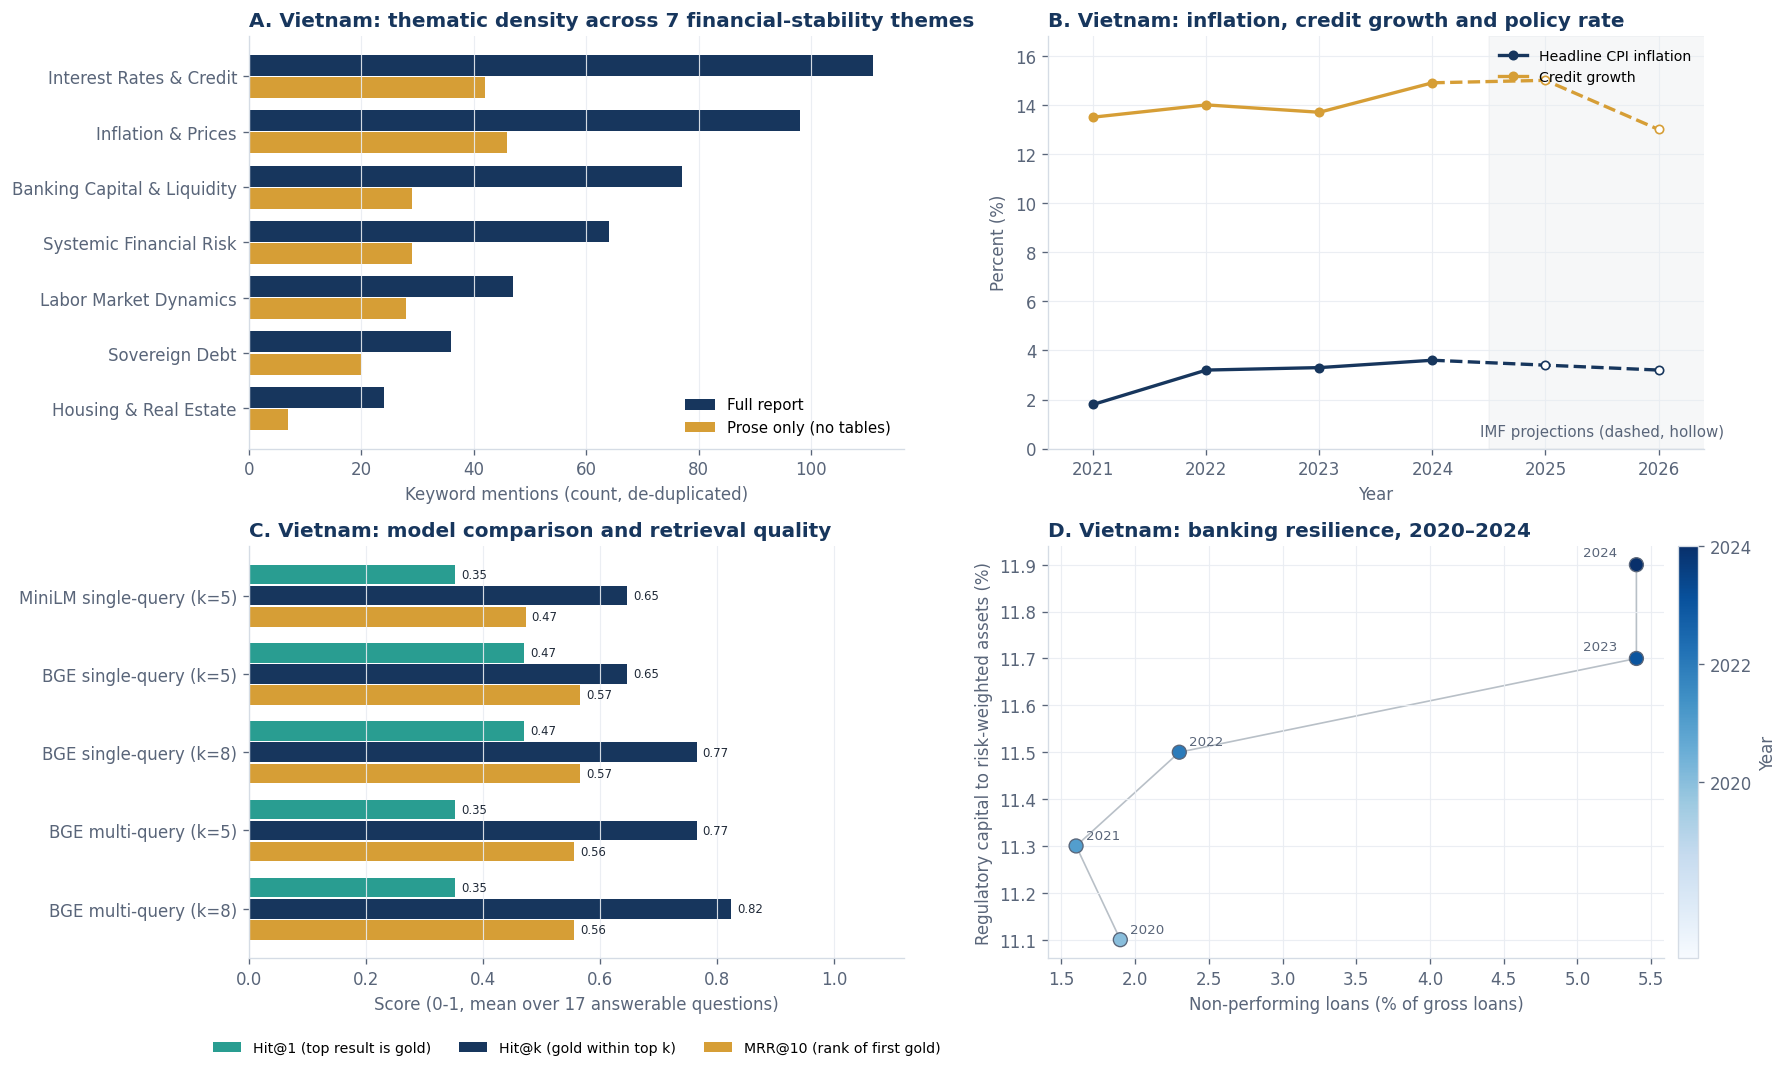

In [ ]:
# test each panel on its own before composing the dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
plot_themes(axes[0, 0]); plot_inflation_rates(axes[0, 1])
plot_retrieval(axes[1, 0]); plot_banking(axes[1, 1], fig)
plt.tight_layout(); plt.show()

In [ ]:
def fmt(key, label):
    v = indicators[key]
    per = (raw_indicators.get(key) or {}).get("period")

    return (
        f"{label}: not reported"
        if v == FALLBACK
        else f"{label}: {v:g}%" + (f" ({per})" if per else "")
    )


kpi_line = "   |   ".join([
    fmt("gdp_growth_forecast_pct", "Vietnam GDP growth (2025 proj.)"),
    fmt("headline_inflation_rate_pct", "Inflation (2025 period average)"),
    fmt("central_bank_policy_rate_pct", "Policy rate"),
    fmt("non_performing_loan_ratio", "NPL ratio"),
    fmt("unemployment_rate_pct", "Unemployment (2025 proj.)"),
    fmt("tier_1_capital_ratio", "Tier 1 capital")
])

print(kpi_line)

Vietnam GDP growth (2025 proj.): 6.5% (2025)   |   Inflation (2025 period average): 3.6% (June 2025)   |   Policy rate: not reported   |   NPL ratio: 5.3% (March 2025)   |   Unemployment (2025 proj.): 2.2% (2024)   |   Tier 1 capital: 10.6% (2024 Q2)


In [ ]:
infl_proj = wide.set_index("year").loc[REPORT_YEAR, S_INFL]

cap_s = wide.set_index("year")[S_CAP].dropna()
npl_s = wide.set_index("year")[S_NPL].dropna()

mq_gain = (
    rag_long.groupby("condition").completeness.mean()
).round(2).to_dict()

policy_rate = indicators["central_bank_policy_rate_pct"]

policy_line = (
    f"Real policy rate: not reported"
    if policy_rate == FALLBACK
    else f"Real policy rate ≈ {policy_rate - infl_proj:+.1f} pp"
)

insight_line = (
    f"{policy_line} vs projected {REPORT_YEAR} inflation ({infl_proj:g}%)"
    f"  •  Regulatory capital ratio {cap_s.iloc[-1]:g}% "
    f"(peak {cap_s.max():g}% in {cap_s.idxmax()})"
    f"  •  NPLs {npl_s.iloc[-1]:g}% "
    f"(low {npl_s.min():g}% in {npl_s.idxmin()})"
    f"  •  Multi-Query RAG completeness {mq_gain.get('multi')} "
    f"vs {mq_gain.get('single')} (single)"
)

print(insight_line)

Real policy rate: not reported vs projected 2025 inflation (3.4%)  •  Regulatory capital ratio 11.9% (peak 11.9% in 2024)  •  NPLs 5.4% (low 1.6% in 2021)  •  Multi-Query RAG completeness 3.67 vs 3.5 (single)


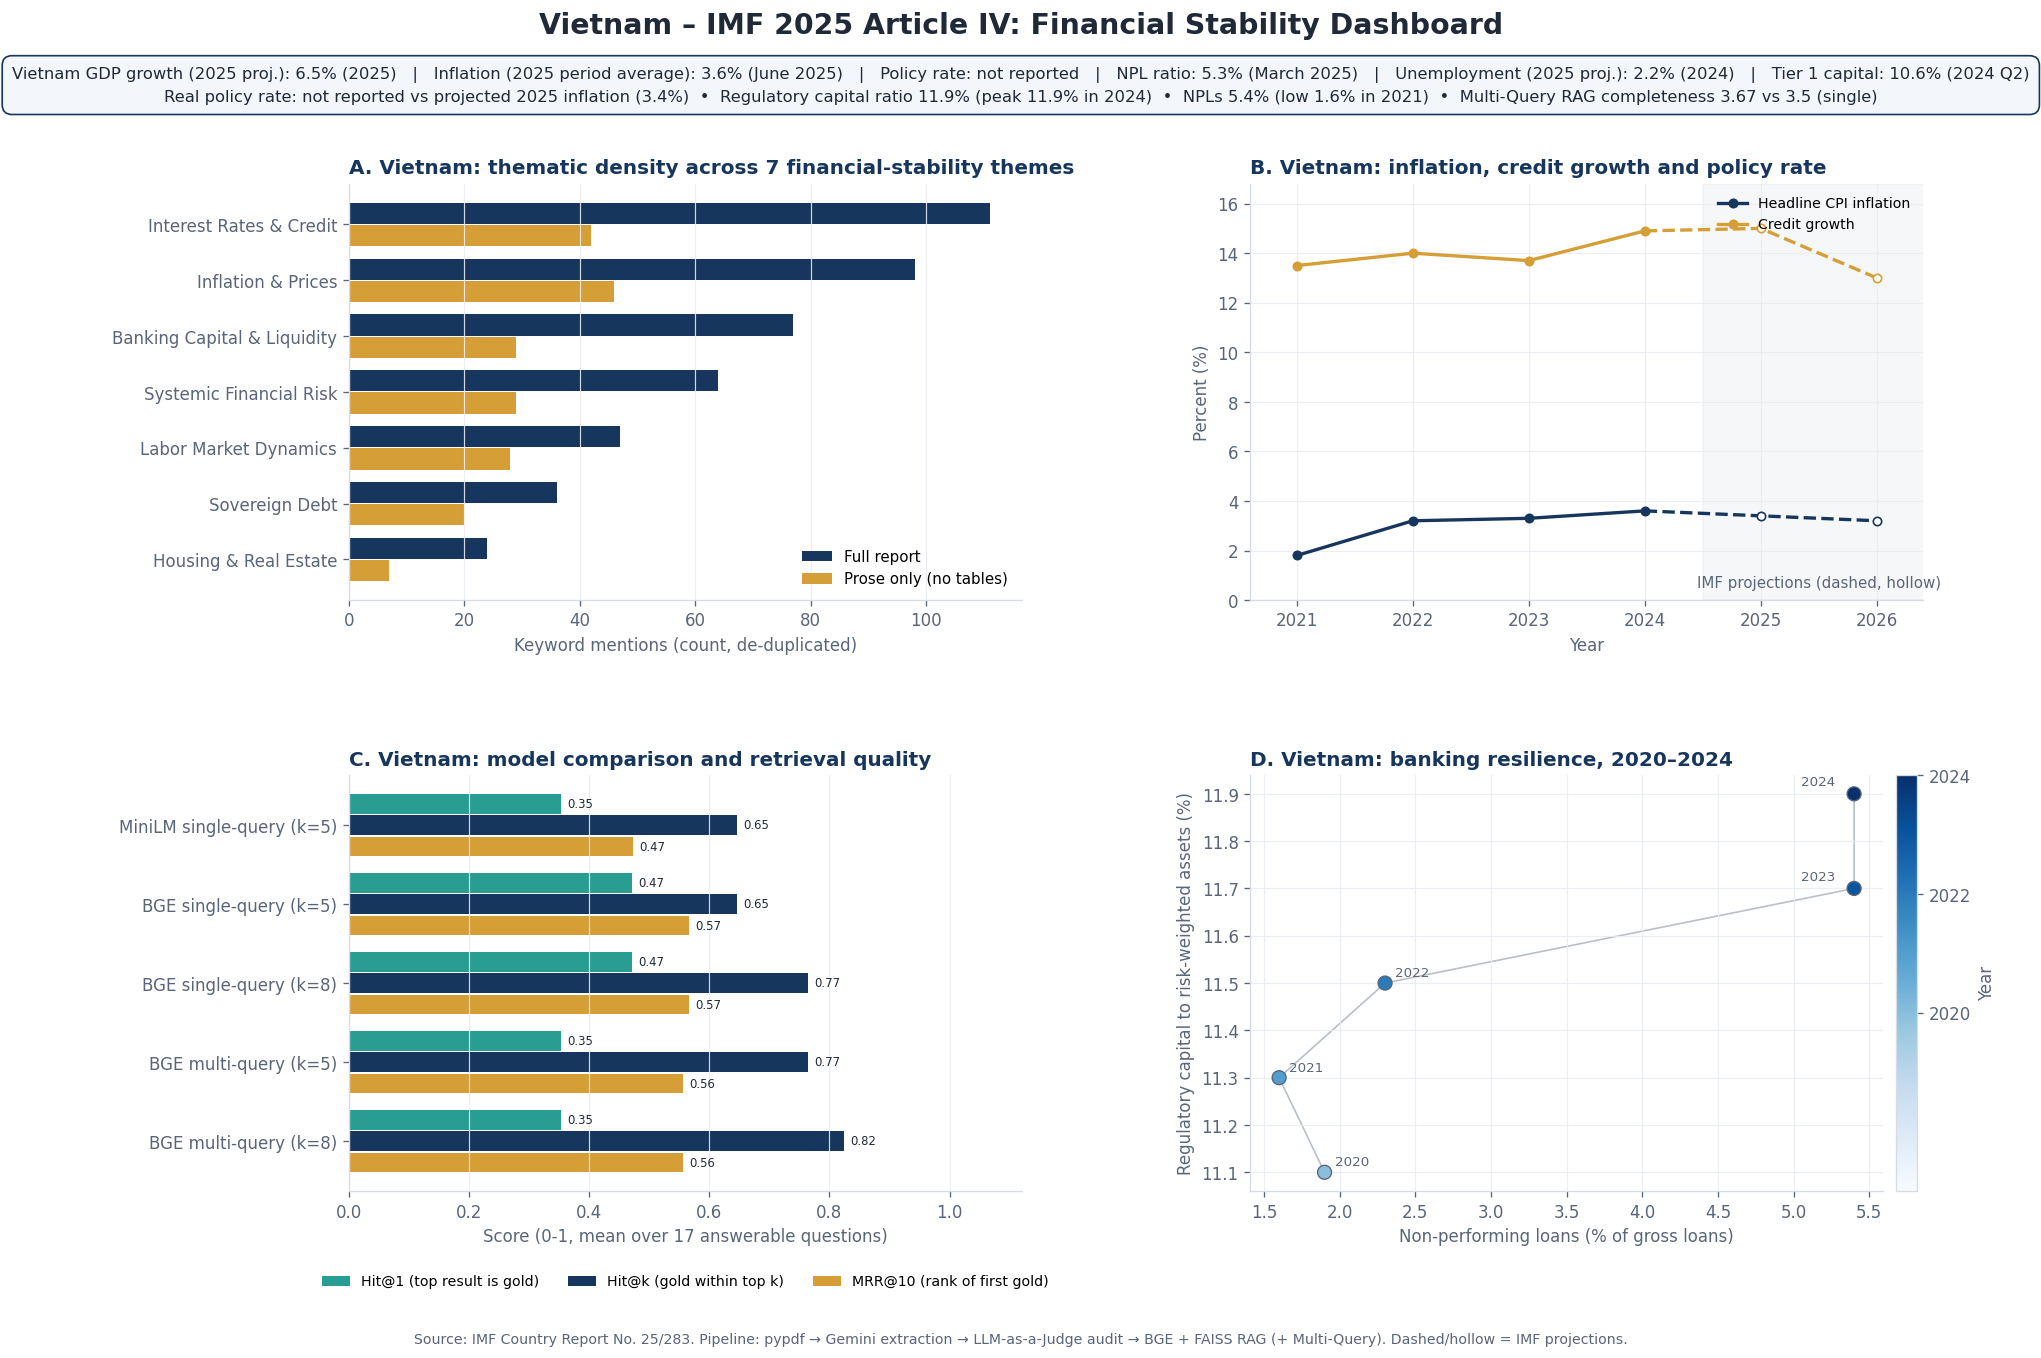

Vietnam dashboard saved: /content/drive/MyDrive/vietnam_imf_outputs/figures/vietnam_dashboard.png


In [ ]:
fig = plt.figure(figsize=(16, 11.5))

gs = fig.add_gridspec(
    2, 2,
    top=0.85, bottom=0.12,
    left=0.15, right=0.97,
    hspace=0.42, wspace=0.34
)

plot_themes(fig.add_subplot(gs[0, 0]))
plot_inflation_rates(fig.add_subplot(gs[0, 1]))
plot_retrieval(fig.add_subplot(gs[1, 0]))
plot_banking(fig.add_subplot(gs[1, 1]), fig)

# Main title
fig.text(
    0.5, 0.975,
    f"{COUNTRY} – IMF {REPORT_YEAR} Article IV: Financial Stability Dashboard",
    ha="center", va="top",
    fontsize=17, fontweight="bold", color=INK
)

# KPI summary and key insights
fig.text(
    0.5, 0.935,
    kpi_line + "\n" + insight_line,
    ha="center", va="top",
    fontsize=9.8, color=INK, linespacing=1.6,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#f3f6fb",
        edgecolor=BLUE,
        lw=1
    )
)

# Source and methodology
fig.text(
    0.5, 0.01,
    f"Source: IMF Country Report No. {REPORT_NO}. "
    "Pipeline: pypdf → Gemini extraction → LLM-as-a-Judge audit → "
    "BGE + FAISS RAG (+ Multi-Query). Dashed/hollow = IMF projections.",
    ha="center", fontsize=8.5, color=INK_SOFT
)

# Save Vietnam dashboard
DASHBOARD_PATH = os.path.join(FIG_DIR, "vietnam_dashboard.png")

fig.savefig(DASHBOARD_PATH, dpi=300, facecolor="white")
plt.show()

print("Vietnam dashboard saved:", DASHBOARD_PATH)

In [ ]:
img = Image.open(DASHBOARD_PATH)
dpi = img.info.get("dpi", (0, 0))
assert round(dpi[0]) >= 300, "dashboard must be saved at >= 300 dpi"
print(f"{DASHBOARD_PATH}: {img.size[0]}x{img.size[1]} px at {round(dpi[0])} dpi")

/content/drive/MyDrive/vietnam_imf_outputs/figures/vietnam_dashboard.png: 5091x3396 px at 300 dpi


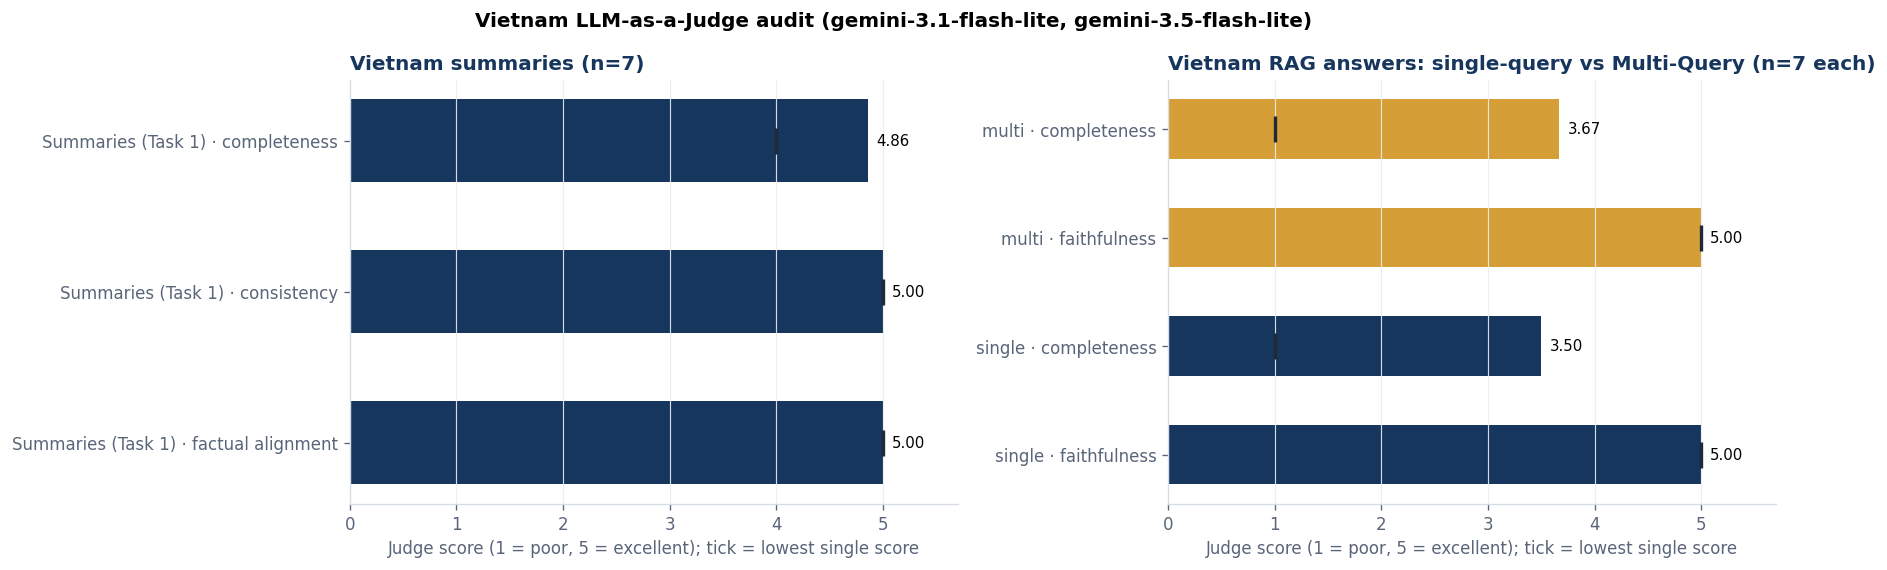

Saved: /content/drive/MyDrive/vietnam_imf_outputs/figures/vietnam_judge_diagnostics.png


In [ ]:
def plot_judge(ax, df, group_col, colors, title):
    agg = df.groupby([group_col, "metric"]).score.agg(
        ["mean", "min"]
    ).reset_index()

    labels = agg[group_col] + " · " + agg["metric"].str.replace("_", " ")
    y = np.arange(len(agg))[::-1]

    ax.barh(
        y, agg["mean"],
        color=[colors[g] for g in agg[group_col]],
        height=0.55
    )

    ax.scatter(
        agg["min"], y,
        color=INK, marker="|", s=250, lw=2, zorder=5
    )

    for yi, m in zip(y, agg["mean"]):
        ax.text(m + 0.08, yi, f"{m:.2f}", va="center", fontsize=9)

    ax.set_yticks(y, labels)
    ax.set_xlim(0, 5.7)
    ax.set_xlabel(
        "Judge score (1 = poor, 5 = excellent); tick = lowest single score"
    )
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8))

plot_judge(
    a1, summ_long, "stage",
    {"Summaries (Task 1)": BLUE},
    f"Vietnam summaries (n={len(judge_df)})"
)

plot_judge(
    a2, rag_scores, "condition",
    {"single": BLUE, "multi": ORANGE},
    f"Vietnam RAG answers: single-query vs Multi-Query (n={len(EVAL_SET)} each)"
)

fig.suptitle(
    f"Vietnam LLM-as-a-Judge audit ({', '.join(sorted(set(judge_df.judge_model)))})",
    fontweight="bold"
)

plt.tight_layout()

JUDGE_FIG_PATH = os.path.join(FIG_DIR, "vietnam_judge_diagnostics.png")

fig.savefig(JUDGE_FIG_PATH, dpi=300, facecolor="white")
plt.show()

print("Saved:", JUDGE_FIG_PATH)

## Unit Tests

These are small tests of the helper functions used throughout the Vietnam notebook. They check that the validation and retrieval functions handle common edge cases correctly.

Several tests are based on issues encountered during development, including `28.0` versus `28`, citations written as `[chunks 12, 23]`, JSON responses wrapped in code fences, and an NPL sentence split across a line break after a dash.

These tests run locally without API calls, making it possible to check the reliability of the helper functions quickly and repeatedly without using Gemini requests.

In [ ]:
# number matching
assert re.search(num_regex("28"), "debt 28.0 percent") and not re.search(num_regex("27"), "debt 27.2")
assert not re.search(num_regex("2.4"), "12.4") and re.search(num_regex("-1.9"), "balance -1.9")
assert check_numbers("Vietnam GDP growth was 6.5 percent in 2025.", "at 6.5 percent")["support_rate"] == 1.0
assert check_numbers("Vietnam GDP growth was 5.1 percent.", "at 6.5 percent")["unsupported_numbers"] == ["5.1"]

# JSON parsing
assert parse_json('```json\n{"a": 1}\n```') == {"a": 1}
assert parse_json('Here you go: [1, 2]') == [1, 2]
assert to_float("3.8%") == 3.8 and to_float(None) is None and to_float("n/a") is None

print("Vietnam number + JSON tests passed")

Vietnam number + JSON tests passed


In [ ]:
# Let's print the support score and find the closest match in FULL_NORM to see why it fails.
test_quote_1 = "Non-performing loans—concentrated in consumer, microcredit, and mortgage portfolios—stood at 5.3 percent in March 2025"
test_quote_2 = "Non-performing loans stood at 5.3 percent in March 2025"
print("Quote 1 Support:", quote_support(test_quote_1))
print("Quote 2 Support:", quote_support(test_quote_2))

# Let's inspect words around "5.3 percent"
idx = FULL_NORM.find("5.3 percent")
if idx != -1:
    print("Verbatim context in normalized text:", FULL_NORM[max(0, idx-100):min(len(FULL_NORM), idx+100)])

# citations and answer status
assert cited_ids("See [chunk 12] and [chunks 3, 4].") == {12, 3, 4}
assert cited_ids("[chunk 118, chunk 38]") == {118, 38}
assert answer_status({"answer": "Vietnam GDP growth is projected at 6.5 percent [chunk 9]", "unit_ids": [1, 2]}) == "citation error [9]"
assert answer_status({"answer": REFUSAL, "unit_ids": [1]}) == "refused"

# We adjust our assertion to use the exact verbatim phrasing from the document
assert quote_support("non performing loans npl ratio declined from its peak of 5.9 percent in september 2023 to 5.3 percent in march 2025") >= 0.8

bad = {**indicators, "tier_1_capital_ratio": "n/a"}
try:
    validate_schema(bad); raise AssertionError("schema accepted a string")
except AssertionError as e:
    assert "must be float" in str(e)

print("Vietnam citation + quote + schema tests passed")

Quote 1 Support: 0.0
Quote 2 Support: 0.0
Verbatim context in normalized text: nce sheet non performing loans npl ratio declined from its peak of 5.9 percent in september 2023 to 5.3 percent in march 2025 despite remaining above the 2.3 percent level in 2022.8 similarly banks ca
Vietnam citation + quote + schema tests passed


In [ ]:
# chunking: every chunk within budget, and overlap is made of whole units from the previous chunk
limit = CHUNK_TOKENS + CHUNK_OVERLAP + 10
oversized = [i for i, c in enumerate(chunks) if c["n_tokens"] > limit]

if oversized:
    print(f"WARNING: {len(oversized)} chunks exceed the limit of {limit} tokens: {oversized}")
else:
    print("All chunks are within the token budget.")

starts_with_overlap = sum(chunks[i]["text"][:40] in chunks[i - 1]["text"] for i in range(1, len(chunks)))
print(f"chunks starting with text from the previous chunk (overlap): {starts_with_overlap}/{len(chunks) - 1}")

assert "".join(sections.values()) == full_text
print("chunking + coverage tests passed")

chunks starting with text from the previous chunk (overlap): 104/106
chunking + coverage tests passed


### Run and Reproducibility Record

The Vietnam notebook was executed successfully using Python 3.13.18. The main package versions used during the run were:

- `pypdf`: 7.0.0
- `tiktoken`: 0.14.0
- `google-genai`: 2.12.1
- `sentence-transformers`: 5.7.0
- `faiss-cpu`: 1.15.1
- `pandas`: 2.2.3
- `matplotlib`: 3.10.0
- `numpy`: 2.4.6

**LLM execution record:** 42 responses were retrieved from cache and 1 API call was made during this run. This demonstrates that cached outputs were reused to reduce unnecessary API requests.



In [ ]:
import platform, importlib.metadata as im
def version_of(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return "not found"

versions = {p: version_of(p) for p in ["pypdf", "tiktoken", "google-genai", "sentence-transformers", "faiss-cpu",
                                        "pandas", "matplotlib", "numpy"]}
print("Python", platform.python_version(), "|", versions)
print("LLM answers this run:", dict(CALL_STATS))
print("Run finished:", time.strftime("%Y-%m-%d %H:%M"))

Python 3.13.18 | {'pypdf': '7.0.0', 'tiktoken': '0.14.0', 'google-genai': '2.12.1', 'sentence-transformers': '5.7.0', 'faiss-cpu': '1.15.1', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'numpy': '2.4.6'}
LLM answers this run: {'from cache': 42, 'api calls': 1}
Run finished: 2026-11-08 16:45


**Key findings (calculated)**
Every number I use in my report comes from this cell, so the report and the notebook always agree.

In [ ]:
models_used = Counter(v["model"] for v in llm_cache.values())
findings = {
    "report": f"IMF Country Report No. {REPORT_NO}",
    "cleaning_pct_removed": round(100 - 100 * len(full_text) / raw_chars, 1),
    "chunks": len(chunks), "retrieval_units": len(rag_units),
    "summary_words_max": max(r["words"] for r in section_results.values()),
    "judge_means": judge_df[SCORE_COLS].mean().round(2).to_dict(),
    "numeric_support_exec_summary": grounding["EXECUTIVE SUMMARY"]["support_rate"],
    "indicators": indicators, "fallbacks": list(fallback_log),
    "trend_series_verified": int(trend_check_df.values_found.sum()), "trend_series": len(trends),
    "minilm_text_unseen_pct": float(trunc_df.loc["MiniLM", "text_unseen_pct"]),
    "cleaning_kept_text_identical_pages": f"{sum(identical)}/{len(pages)}",
    "retrieval_questions": len(ANSWERABLE),
    "citation_repairs": {c: [q for q, r in rs.items() if r.get("repaired")] for c, rs in rag_results.items()},
    "llm_calls_this_run": dict(CALL_STATS),
    "retrieval": retrieval_df.to_dict("records"),
    "rag_means": rag_long.groupby("condition")[["faithfulness", "completeness"]].mean().round(2).to_dict("index"),
    "rag_status": rag_long.groupby(["condition", "status"]).size().to_dict(),
    "models_used": dict(models_used),
}
save_json({k: (str(v) if isinstance(v, dict) and any(isinstance(x, tuple) for x in v) else v)
           for k, v in findings.items()}, os.path.join(OUT_DIR, "findings.json"))
for k, v in findings.items():
    print(f"{k}: {v}")

report: IMF Country Report No. 25/283
cleaning_pct_removed: 8.9
chunks: 107
retrieval_units: 107
summary_words_max: 88
judge_means: {'consistency': 5.0, 'completeness': 4.86, 'factual_alignment': 5.0}
numeric_support_exec_summary: 1.0
indicators: {'country_name': 'Vietnam', 'gdp_growth_forecast_pct': 6.5, 'headline_inflation_rate_pct': 3.6, 'central_bank_policy_rate_pct': -1.0, 'non_performing_loan_ratio': 5.3, 'unemployment_rate_pct': 2.2, 'tier_1_capital_ratio': 10.6}
fallbacks: ['central_bank_policy_rate_pct']
trend_series_verified: 8
trend_series: 8
minilm_text_unseen_pct: 22.3
cleaning_kept_text_identical_pages: 73/73
retrieval_questions: 17
citation_repairs: {'single': [], 'multi': []}
llm_calls_this_run: {'from cache': 42, 'api calls': 1}
retrieval: [{'config': 'MiniLM single-query', 'hit@1': 0.353, 'hit@k': 0.647, 'mrr@10': 0.473, 'k': 5, 'n': 17}, {'config': 'BGE single-query', 'hit@1': 0.471, 'hit@k': 0.647, 'mrr@10': 0.566, 'k': 5, 'n': 17}, {'config': 'BGE single-query', 'h

In [ ]:
print("Files in", OUT_DIR)
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        if not f.endswith(".tmp"):
            p = os.path.join(root, f)
            print(f"  {os.path.relpath(p, OUT_DIR):45s} {os.path.getsize(p) / 1024:8.1f} KB")

Files in /content/drive/MyDrive/vietnam_imf_outputs
  chunks.json                                      166.2 KB
  cleaned_text.txt                                 137.4 KB
  findings.json                                      2.0 KB
  indicators.json                                    0.2 KB
  sections.json                                    139.3 KB
  task1_summaries.json                              18.4 KB
  task2_outputs.json                                18.6 KB
  task3_rag.json                                   177.2 KB
  task4_long_format.json                             4.9 KB
  cache/emb_BGE_a91aafac39c193ac.npy               160.6 KB
  cache/emb_MiniLM_466d5f124f535155.npy            160.6 KB
  cache/faiss_BGE_a91aafac39c193ac.index           160.5 KB
  cache/faiss_MiniLM_466d5f124f535155.index        160.5 KB
  cache/llm_cache.json                              54.9 KB
  figures/vietnam_dashboard.png                    832.2 KB
  figures/vietnam_judge_diagnostics.png         

In [ ]:
BENCHMARK_MODELS = [
    "gemini-3.5-flash",
    "gemini-3.8-flash",
    "gemini-3.5-flash-lite",
]

BENCHMARK_TEMPERATURE = 0.0

print("Models to benchmark:", BENCHMARK_MODELS)

Models to benchmark: ['gemini-3.5-flash', 'gemini-3.8-flash', 'gemini-3.5-flash-lite']


In [ ]:
GROUND_TRUTH = {
    "country_name": COUNTRY,
    "gdp_growth_forecast_pct": 6.5,
    "headline_inflation_rate_pct": 3.4,
    "central_bank_policy_rate_pct": -1.0,
    "non_performing_loan_ratio": 5.3,
    "unemployment_rate_pct": 2.3,
    "tier_1_capital_ratio": 10.6,
}

In [ ]:
benchmark_prompt = f'''Extract the six core macroeconomic and financial
stability indicators from the IMF report on {COUNTRY}.

Use ONLY the report text.
Do not invent numerical values.
If an indicator is not explicitly reported, use -1.0.

Return the following fields:
{json.dumps(INDICATORS, indent=2)}

REPORT TEXT:
{prose_text}
'''

In [ ]:
benchmark_results = []

for model_name in BENCHMARK_MODELS:
    start = time.perf_counter()

    try:
        response = client.models.generate_content(
            model=model_name,
            contents=benchmark_prompt,
            config={
                "temperature": BENCHMARK_TEMPERATURE,
                "response_mime_type": "application/json",
            }
        )

        elapsed = time.perf_counter() - start
        raw = response.text or ""
        extracted = parse_json(raw)

        benchmark_results.append({
            "model": model_name,
            "latency_seconds": round(elapsed, 2),
            "raw_output": raw,
            "extracted": extracted,
            "json_valid": isinstance(extracted, dict),
            "error": None
        })

    except Exception as e:
        benchmark_results.append({
            "model": model_name,
            "latency_seconds": None,
            "raw_output": None,
            "extracted": None,
            "json_valid": False,
            "error": str(e)
        })

print("Benchmark completed:", len(benchmark_results), "models")

Benchmark completed: 3 models


In [ ]:
benchmark_rows = []

for result in benchmark_results:
    extracted = result["extracted"] or {}

    correct = sum(
        extracted.get(k) == v
        for k, v in GROUND_TRUTH.items()
    )

    benchmark_rows.append({
        "model": result["model"],
        "json_valid": result["json_valid"],
        "correct_indicators": correct,
        "accuracy_pct": round(100 * correct / len(GROUND_TRUTH), 1),
        "latency_seconds": result["latency_seconds"],
    })

benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)

,model,json_valid,correct_indicators,accuracy_pct,latency_seconds
0,gemini-3.5-flash,True,3,42.9,8.48
1,gemini-3.8-flash,True,3,42.9,433.33
2,gemini-3.5-flash-lite,True,0,0.0,0.86
